# Santander Customer Satisfaction - Predicting Unhappy Customers

**Author:** Andre Kim Scarton

## What this project is about

Santander wants to know which customers are unhappy **before** they close their accounts and
leave. Unhappy customers almost never complain first - they just quietly walk away. If the bank
can spot the warning signs early, someone can actually call the customer, fix whatever's wrong, and
keep them around.

This is my walkthrough of the [Kaggle Santander Customer Satisfaction dataset](https://www.kaggle.com/c/santander-customer-satisfaction):
76,020 customers, 370 anonymized numeric columns, and one label - `TARGET` - which is `1` if the
customer ended up dissatisfied and `0` if they didn't. The column names are all anonymized
(`var15`, `saldo_var30`, etc.), so there's no domain knowledge to lean on here - every decision
below is based purely on what the numbers show.

## The metric I'm optimizing for

Only about 4% of customers in this dataset are actually dissatisfied. That number matters a lot:
a model that just guesses "satisfied" for everyone would be right 96% of the time and still be
completely useless, because it would never catch a single unhappy customer. So accuracy is out.
I used **ROC-AUC** as my main metric instead - it measures how well a model *ranks* customers from
least to most likely to be dissatisfied, which is what actually matters here, and it's also the
metric Kaggle used to score this competition. Later on I also bring in Precision-Recall, which
turned out to give a more honest read given how rare the positive class is.

## How I structured this notebook

1. Setup & imports
2. Loading the data
3. First look - shape, types, and how imbalanced the target really is
4. Cleaning the data and spotting two data-quality issues worth digging into
5. Splitting into training and validation sets (and why I do this *before* touching the features)
6. Fixing the two issues from step 4 and engineering two new features
7. Picking the final set of variables using four different statistical tests
8. Getting the data ready for modeling - scaling and handling the class imbalance
9. Training and comparing six different models
10. Comparing the models properly - not just eyeballing one score each
11. Checking whether the winning model is *actually* better, or just got lucky
12. Testing whether SMOTE was the right call, or whether something simpler works better
13. Turning the model's output into an actual "who do I call first" list
14. Looking at what the final model is actually paying attention to
15. Retraining on all the data and building the Kaggle submission
16. What I'd do with more time

I tried to explain every non-obvious decision as I go, in plain language - the idea is that anyone,
technical or not, can follow *why* I did something, not just *what* the code does.

**To run this yourself:** drop `train.csv`, `test.csv` and `sample_submission.csv` into a `data/`
folder next to this notebook. Trained models and the submission file get written to `models/` and
`output/`.

## 1. Setup & Imports

Everything I need is imported up front, with a short note on why each one is there - useful if
you're not familiar with some of these libraries.

One thing worth explaining: I set a fixed **random seed** (`RANDOM_STATE = 42`) right at the start.
A lot of steps here involve randomness - splitting the data, oversampling, training the models,
the bootstrap test later on. Fixing the seed doesn't make things "less random" - it just means that
if you (or I) run this notebook again, I get the exact same split and the exact same numbers.
Without it, every re-run would shuffle things slightly differently and I'd never know if a change
in results came from something I actually did, or just from luck of the draw.

In [1]:
# --- Core data handling ---
import numpy as np                # numeric arrays and fast vectorised math
import pandas as pd               # tables (DataFrames) - how I load and manipulate the dataset

# --- Visualization ---
import matplotlib.pyplot as plt   # base plotting library
import seaborn as sns             # statistical plots built on top of matplotlib (nicer defaults)

# --- Statistics ---
from scipy import stats           # Mann-Whitney U test, etc.

# --- Preprocessing & pipelines ---
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import mutual_info_classif
# imblearn's Pipeline (not sklearn's) is needed because it knows how to chain a
# resampling step (SMOTE) together with a scaler and a classifier. A normal sklearn
# Pipeline does not support resampling steps.
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

# --- Model selection ---
from sklearn.model_selection import (
    train_test_split, GridSearchCV, RandomizedSearchCV, cross_val_score
)

# --- Models I will compare ---
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC

# --- Evaluation metrics ---
from sklearn.metrics import (
    roc_auc_score, roc_curve, auc, accuracy_score,
    ConfusionMatrixDisplay, precision_recall_curve, average_precision_score, brier_score_loss
)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

# --- Persisting the trained model to disk ---
import joblib

# --- Misc ---
import warnings
import os

warnings.filterwarnings("ignore")   # sklearn/imblearn are chatty with future-version warnings;
                                     # I silence them here so the notebook output stays readable,
                                     # but this is a deliberate choice, not a way of hiding bugs.

RANDOM_STATE = 42     # used everywhere I need randomness, so results are reproducible
pd.set_option("display.max_columns", 60)

# Folder layout for this project (created if missing)
DATA_DIR = "data"
MODEL_DIR = "models"
OUTPUT_DIR = "output"
for d in (DATA_DIR, MODEL_DIR, OUTPUT_DIR):
    os.makedirs(d, exist_ok=True)

sns.set_theme(style="whitegrid")

## 2. Loading the data

I load the training set (which has the `TARGET` label, so I can teach a model with it) and the
Kaggle test set (which does not have `TARGET` — that's what I must predict at the very end).

In [2]:
train_raw = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
test_raw = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))

print(f"train_raw shape: {train_raw.shape}")
print(f"test_raw shape:  {test_raw.shape}")

train_raw shape: (76020, 371)
test_raw shape:  (75818, 370)


In [3]:
train_raw.head()

,ID,var3,var15,imp_ent_var16_ult1,imp_op_var39_comer_ult1,imp_op_var39_comer_ult3,imp_op_var40_comer_ult1,imp_op_var40_comer_ult3,imp_op_var40_efect_ult1,imp_op_var40_efect_ult3,imp_op_var40_ult1,imp_op_var41_comer_ult1,imp_op_var41_comer_ult3,imp_op_var41_efect_ult1,imp_op_var41_efect_ult3,imp_op_var41_ult1,imp_op_var39_efect_ult1,imp_op_var39_efect_ult3,imp_op_var39_ult1,imp_sal_var16_ult1,ind_var1_0,ind_var1,ind_var2_0,ind_var2,ind_var5_0,ind_var5,ind_var6_0,ind_var6,ind_var8_0,ind_var8,...,saldo_medio_var13_corto_hace2,saldo_medio_var13_corto_hace3,saldo_medio_var13_corto_ult1,saldo_medio_var13_corto_ult3,saldo_medio_var13_largo_hace2,saldo_medio_var13_largo_hace3,saldo_medio_var13_largo_ult1,saldo_medio_var13_largo_ult3,saldo_medio_var13_medio_hace2,saldo_medio_var13_medio_hace3,saldo_medio_var13_medio_ult1,saldo_medio_var13_medio_ult3,saldo_medio_var17_hace2,saldo_medio_var17_hace3,saldo_medio_var17_ult1,saldo_medio_var17_ult3,saldo_medio_var29_hace2,saldo_medio_var29_hace3,saldo_medio_var29_ult1,saldo_medio_var29_ult3,saldo_medio_var33_hace2,saldo_medio_var33_hace3,saldo_medio_var33_ult1,saldo_medio_var33_ult3,saldo_medio_var44_hace2,saldo_medio_var44_hace3,saldo_medio_var44_ult1,saldo_medio_var44_ult3,var38,TARGET
0,1,2,23,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,1,0,0,0,0,0,...,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,39205.170000,0
1,3,2,34,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,1,0,0,0,0,0,...,300.0,122.22,300.0,240.75,0.0,0.0,0.0,0.0,0.0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,49278.030000,0
2,4,2,23,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,1,1,0,0,0,0,...,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,67333.770000,0
3,8,2,37,0.0,195.0,195.0,0.0,0.0,0.0,0.0,0.0,195.0,195.0,0.0,0.0,195.0,0.0,0.0,195.0,0.0,0,0,0,0,1,1,0,0,0,0,...,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,64007.970000,0
4,10,2,39,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,1,0,0,0,0,0,...,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,117310.979016,0


## 3. First look at the data

Before touching anything, I want basic questions answered:

- How many rows and columns are there?
- What data types do I have (all numeric? any text)?
- Are there missing values?
- Are there duplicate customer records?
- How imbalanced is the target?

Answering these first prevents me from designing a strategy (e.g. an elaborate missing-value
imputer) for a problem the data doesn't actually have.

In [4]:
# All columns and their dtypes in one place
train_raw.info(memory_usage="deep")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76020 entries, 0 to 76019
Columns: 371 entries, ID to TARGET
dtypes: float64(111), int64(260)
memory usage: 215.2 MB


In [5]:
# This dataset happens to be 100% numeric (no text/categorical columns) — every feature has
# already been encoded as a number by the bank before the data was published.
non_numeric_cols = train_raw.select_dtypes(exclude=[np.number]).columns.tolist()
print("Non-numeric columns:", non_numeric_cols if non_numeric_cols else "None — every column is numeric.")

Non-numeric columns: None — every column is numeric.


In [6]:
# Classic missing-value check: how many cells are NaN?
n_missing = train_raw.isnull().sum().sum()
print(f"Total missing (NaN) cells in train: {n_missing}")

# Duplicate customer rows (identical across every single column)?
n_dupe_rows = train_raw.duplicated().sum()
print(f"Fully duplicated rows in train: {n_dupe_rows}")

Total missing (NaN) cells in train: 0


Fully duplicated rows in train: 0


**Reading the result above:** there are zero `NaN` cells and zero duplicated rows. That does
**not** mean the data is perfectly clean, though — anonymized banking datasets like this one often
hide missing values behind a placeholder number instead of a real `NaN` (I investigate this in
Section 4.3), and they often contain redundant columns that are technically not "duplicate rows"
but are still redundant information (Section 4.2). A quick `isnull()` check is a start, not the
end, of a data-quality audit.

### 3.1 Target variable balance

This is the single most important number in the whole notebook: **what fraction of customers are
dissatisfied?** It shapes almost every later decision — which metric to use, whether to rebalance
the training data, and how to interpret the confusion matrix.

Counts:
 TARGET
0    73012
1     3008
Name: count, dtype: int64

Percentages:
 TARGET
0    96.04
1     3.96
Name: proportion, dtype: float64


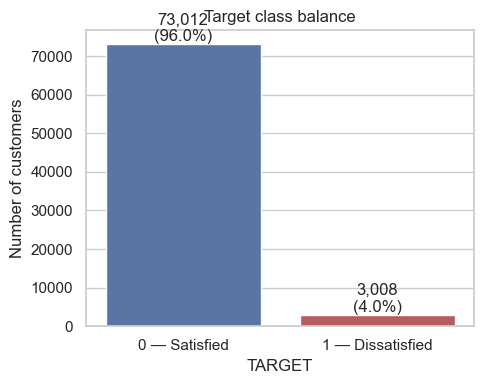

In [7]:
target_counts = train_raw["TARGET"].value_counts()
target_pct = train_raw["TARGET"].value_counts(normalize=True) * 100

print("Counts:\n", target_counts)
print("\nPercentages:\n", target_pct.round(2))

fig, ax = plt.subplots(figsize=(5, 4))
sns.barplot(x=target_counts.index.astype(str), y=target_counts.values, ax=ax,
            palette=["#4C72B0", "#C44E52"])
ax.set_xticklabels(["0 — Satisfied", "1 — Dissatisfied"])
ax.set_ylabel("Number of customers")
ax.set_title("Target class balance")
for i, v in enumerate(target_counts.values):
    ax.text(i, v, f"{v:,}\n({target_pct.values[i]:.1f}%)", ha="center", va="bottom")
plt.tight_layout()
plt.show()

**What this tells me:** only about 4 in 100 customers are dissatisfied. This is a **highly
imbalanced classification problem**. Two consequences follow directly from this number:

1. **Accuracy would be a misleading metric** — always predicting "satisfied" scores ~96% accuracy
   while catching 0 unhappy customers. I use **ROC-AUC** instead (see Section 0).
2. **The learning algorithm barely sees examples of the minority class** during training, which
   tends to make models biased toward always predicting the majority class. I address this later
   (Section 8), and put that choice under a magnifying glass in Section 12.

## 4. Cleaning the data (and spotting two issues to deal with later)

My first instinct with a dataset like this is usually to drop any column that's mostly zeros. I
tried that here too - but it doesn't actually hold up. A lot of these columns look like counts of
products or transactions, so zero is a completely normal, meaningful value (a customer who simply
doesn't have that product), not a missing value in disguise. Dropping columns on a "too many zeros"
rule would throw away real signal for the wrong reason. So instead I clean based on **redundancy**
- columns that carry no information at all, or that are exact duplicates of another column - and
let the feature-selection step in Section 7 (which actually tests each variable statistically)
decide what stays.

This section does two different things, and I'm keeping them separate on purpose:

1. **Stuff I fix right away** - dropping constant columns and duplicate columns. This is safe to do
   before I even split the data, because it never looks at `TARGET` and never computes anything
   that could "leak" information between training and validation - it's just asking "does this
   column carry any information at all?", which is true regardless of how I later split the rows.
2. **Two issues I *notice* here but don't fix yet** - a suspicious placeholder value hiding in
   `var3`, and a badly skewed `var38`. Fixing both means computing something (a fill-in value; a
   transform) that I want learned only from the training data, to keep things honest. Since I
   haven't split the data yet at this point, I just describe what I'm seeing here, and do the
   actual fix in Section 6, right after the split in Section 5.

One more thing I decided against: deleting "outlier" rows. It's tempting, but on anonymized banking
data those extreme values (e.g. a customer with a huge balance) might be exactly the unusual cases
the bank actually cares about - deleting them just because they're far from the average changes
who the model gets evaluated on. For `var38` below, I fix the skew by transforming its *scale*
(a log transform) instead of removing the customers who happen to have big numbers.

### 4.1 Constant columns

In [8]:
# nunique() counts how many *different* values a column has. If a column has only 1 unique
# value across all 76,020 customers, every customer looks identical on that variable - it cannot
# possibly help distinguish a satisfied customer from a dissatisfied one.
nunique = train_raw.drop(columns=["ID", "TARGET"]).nunique()
constant_cols = nunique[nunique == 1].index.tolist()

print(f"Found {len(constant_cols)} constant columns out of {train_raw.shape[1] - 2} features.")
print(constant_cols)

Found 34 constant columns out of 369 features.
['ind_var2_0', 'ind_var2', 'ind_var27_0', 'ind_var28_0', 'ind_var28', 'ind_var27', 'ind_var41', 'ind_var46_0', 'ind_var46', 'num_var27_0', 'num_var28_0', 'num_var28', 'num_var27', 'num_var41', 'num_var46_0', 'num_var46', 'saldo_var28', 'saldo_var27', 'saldo_var41', 'saldo_var46', 'imp_amort_var18_hace3', 'imp_amort_var34_hace3', 'imp_reemb_var13_hace3', 'imp_reemb_var33_hace3', 'imp_trasp_var17_out_hace3', 'imp_trasp_var33_out_hace3', 'num_var2_0_ult1', 'num_var2_ult1', 'num_reemb_var13_hace3', 'num_reemb_var33_hace3', 'num_trasp_var17_out_hace3', 'num_trasp_var33_out_hace3', 'saldo_var2_ult1', 'saldo_medio_var13_medio_hace3']


### 4.2 Duplicate columns

Some columns are exact copies of other columns (same values, in the same order, for every single
customer) — this happens fairly often in datasets assembled by joining several internal source
tables. I detect this by comparing columns pairwise.

In [9]:
# Transposing gives me one row per feature, so pandas' duplicated() can compare entire columns
# against each other in one call (much faster than a manual double loop over 370 columns).
features_only = train_raw.drop(columns=["ID", "TARGET"])
is_dup_column = features_only.T.duplicated()
duplicate_cols = features_only.columns[is_dup_column].tolist()

print(f"Found {len(duplicate_cols)} columns that are exact duplicates of an earlier column.")
print(duplicate_cols[:20], "..." if len(duplicate_cols) > 20 else "")

Found 62 columns that are exact duplicates of an earlier column.
['ind_var2', 'ind_var13_medio', 'ind_var18', 'ind_var26', 'ind_var25', 'ind_var27_0', 'ind_var28_0', 'ind_var28', 'ind_var27', 'ind_var29_0', 'ind_var29', 'ind_var32', 'ind_var34', 'ind_var37', 'ind_var41', 'ind_var39', 'ind_var46_0', 'ind_var46', 'num_var13_medio', 'num_var18'] ...


In [10]:
# Drop constant + duplicate columns. I keep ID and TARGET untouched. This is safe to do before
# the train/validation split (see the explanation above): it's a structural property of the
# columns, not a statistic derived from customers' TARGET values.
cols_to_drop_structural = list(set(constant_cols) | set(duplicate_cols))
train_clean = train_raw.drop(columns=cols_to_drop_structural)

print(f"Removed {len(cols_to_drop_structural)} structurally useless columns "
      f"({len(constant_cols)} constant + {len(duplicate_cols)} duplicate, "
      f"with some overlap removed by the set union).")
print(f"Shape before: {train_raw.shape}  ->  Shape after: {train_clean.shape}")

Removed 63 structurally useless columns (34 constant + 62 duplicate, with some overlap removed by the set union).
Shape before: (76020, 371)  ->  Shape after: (76020, 308)


### 4.3 `var3`: something's off here (fixing it properly in Section 6)

Let's look at what values `var3` actually takes. If it's something like a country or region code,
I'd expect a handful of common values with maybe a long tail of rare ones - I would **not** expect
a value that looks deliberately, obviously unrealistic.

In [11]:
print("var3 - most common values:")
print(train_clean["var3"].value_counts().head(10))
print("\nvar3 - most negative values:")
print(train_clean["var3"].sort_values().head(10).to_string())

var3 - most common values:
var3
 2         74165
 8           138
-999999      116
 9           110
 3           108
 1           105
 13           98
 7            97
 4            86
 12           85
Name: count, dtype: int64

var3 - most negative values:
62305   -999999
14051   -999999
14249   -999999
46395   -999999
52940   -999999
25322   -999999
29716   -999999
12896   -999999
35511   -999999
39604   -999999


**Here's what jumps out:** almost every customer has `var3 = 2`, and then there's a small cluster
of rows sitting at `var3 = -999999` - a number that's wildly out of range compared to everything
else. This is a pretty classic pattern: instead of leaving a proper blank/`NaN`, whoever built this
dataset used an impossible number as a stand-in for "I don't know." I'm going to treat those rows
as missing and fill them in with the most common value (the mode) - but I'm not touching
`train_clean["var3"]` yet. Whatever value I fill in has to come from the training data only, so
that fix waits until Section 6, right after the split.

### 4.4 `var38`: badly skewed (fixing it properly in Section 6)

`var38` looks like some kind of monetary amount - always positive, huge range. Skewed money
variables like this show up constantly in finance, and they're a real problem for models: a
handful of very wealthy customers can dominate the whole variable's scale, drowning out the more
subtle differences among everyone else. This especially hurts models that care about distances or
raw scale, like KNN, SVM, or Logistic Regression.

count    7.602000e+04
mean     1.172358e+05
std      1.826646e+05
min      5.163750e+03
25%      6.787061e+04
50%      1.064092e+05
75%      1.187563e+05
max      2.203474e+07
Name: var38, dtype: float64

Skewness of var38: 51.27  (0 = symmetric; values above ~1 are considered strongly skewed)


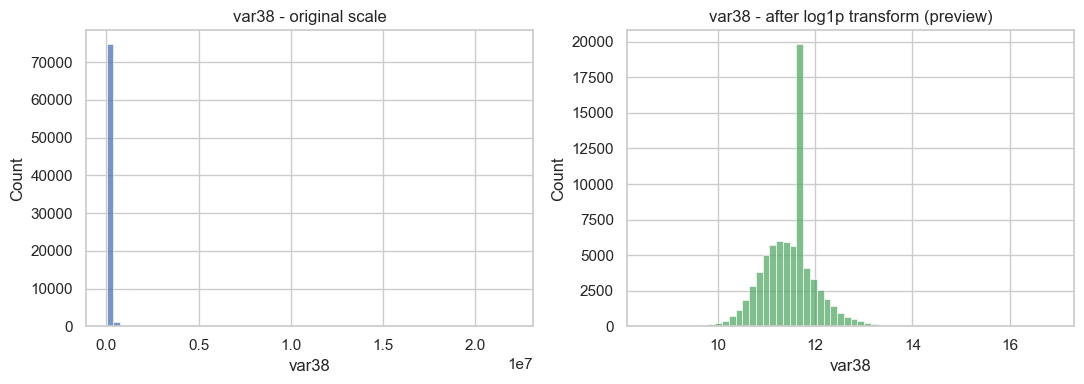

In [12]:
print(train_clean["var38"].describe())
print(f"\nSkewness of var38: {train_clean['var38'].skew():.2f}  "
      f"(0 = symmetric; values above ~1 are considered strongly skewed)")

# Note: this log1p is only computed here, on the fly, to draw the "after" histogram below - I'm
# not saving it into train_clean yet. I apply it for real in Section 6, right alongside the var3
# fix, so all the feature-prep logic lives in one place instead of being scattered around.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(train_clean["var38"], bins=60, ax=axes[0], color="#4C72B0")
axes[0].set_title("var38 - original scale")

sns.histplot(np.log1p(train_clean["var38"]), bins=60, ax=axes[1], color="#55A868")
axes[1].set_title("var38 - after log1p transform (preview)")
plt.tight_layout()
plt.show()

**Why `log1p` and not plain `log`:** `log1p(x)` is `log(1 + x)`. The `+ 1` just avoids a math
error if a value were ever exactly 0 (`log(0)` doesn't exist), and it barely changes anything for
values this large. Looking at the right-hand histogram, that's a much friendlier shape for a model
to work with than the original.

## 5. Splitting into training and validation sets - early, on purpose

I split the data *here*, before doing any feature engineering or feature selection, and that's a
deliberate choice worth explaining, because it's easy to get backwards.

> **Why the split happens before I pick features, not right before modeling:** if I compute
> correlations, statistical tests, mutual information, or feature importance on the *entire*
> dataset and only split afterward, the validation set's `TARGET` values end up quietly
> influencing which features got chosen in the first place - even though that same validation set
> is supposed to be the part of the data the whole pipeline has never seen. That's a subtle form of
> **data leakage**, and it makes the validation score look a little better than it honestly should.
>
> So I split first, and from this point on, anything that "learns" something from the data - the
> value used to fill in `var3`, which features make the cut, which hyperparameters win, how the
> imbalance-handling gets calibrated - is computed **only** from the training fold. The validation
> fold only ever gets used to *score* a finished pipeline, never to help build one. That's exactly
> how it would work in production too: the model is frozen before it ever meets a new customer.

I also use **stratified** sampling (`stratify=y`). Since only about 4% of customers are
dissatisfied, a plain random split could, just by chance, leave the validation set with a
noticeably different ratio - say 3% or 5% instead of 4%. Stratifying keeps both sets at the same
~96/4 split I measured in Section 3, so I'm not adding random noise to my evaluation for no reason.

One more thing worth being explicit about, since it trips people up: setting `random_state=42`
below doesn't make this split "less random." `train_test_split` still shuffles the rows randomly -
the seed just means that shuffle is reproducible, so re-running this notebook gives the same split
instead of a new random one every time. And stratifying isn't "less random" either - it's random
sampling done separately within each class, just to stop the ~4% minority class from being
over- or under-represented by pure chance.

In [13]:
train_part, val_part = train_test_split(
    train_clean, test_size=0.25, stratify=train_clean["TARGET"], random_state=RANDOM_STATE
)
# .copy() avoids "SettingWithCopyWarning" headaches later, when I add engineered columns
# to these slices in Section 6.
train_part = train_part.copy()
val_part = val_part.copy()

print(f"Training fold:   {train_part.shape[0]:,} customers")
print(f"Validation fold: {val_part.shape[0]:,} customers")
print(f"\nTARGET balance in training fold:\n{train_part['TARGET'].value_counts(normalize=True).round(4)}")
print(f"\nTARGET balance in validation fold:\n{val_part['TARGET'].value_counts(normalize=True).round(4)}")

Training fold:   57,015 customers
Validation fold: 19,005 customers

TARGET balance in training fold:
TARGET
0    0.9604
1    0.0396
Name: proportion, dtype: float64

TARGET balance in validation fold:
TARGET
0    0.9604
1    0.0396
Name: proportion, dtype: float64


## 6. Fixing what I found, and adding two new features

Time to actually fix the two things I flagged in Section 4, and add two features of my own. I
wrapped all of it into **one function**, `prepare_features()`, instead of writing separate code
for train/validation/test.

That's not just for tidiness - I reuse this exact same function on the Kaggle test set in Section
15. That guarantees the model always sees data prepared the exact same way, no matter whether it
came from training, validation, or the real test set. It's way too easy, when you write the
cleaning logic twice, for the two copies to quietly drift apart (forget to re-apply the `var3` fix
in one of them, for instance) - one shared function makes that kind of mistake impossible.

**The two features I added:**

- **`var38_log`** - the log version of `var38`, fixing the skew from Section 4.4. I keep the
  original `var38` around too and let Section 7 decide which one (or both) is actually worth
  keeping.
- **`n_zeros`** - for each customer, a count of how many of their columns are exactly zero. My
  reasoning: a lot of these anonymized columns look like counts of products or transactions, so a
  customer with a ton of zeros probably has very little going on with the bank, versus someone who
  actively uses lots of products. That's a pattern that's invisible in any single column, but shows
  up clearly once you count across all of them.

In [14]:
SENTINEL = -999999

def prepare_features(df_raw, var3_mode_value):
    # Applies the var3 missing-value fix and adds the two engineered columns. var3_mode_value
    # must be supplied by the caller (learned from training data only - see below) so this
    # function never has the chance to "peek" at whichever dataset it's currently preparing.
    df = df_raw.copy()

    # 4.3 fix - replace the missing-value sentinel with the training-fold mode
    df["var3"] = df["var3"].replace(SENTINEL, var3_mode_value)

    # 4.4 fix - log-transform the skewed monetary variable (a fixed formula, not a learned
    # statistic, so it needs no train-only fitting)
    df["var38_log"] = np.log1p(df["var38"])

    # Engineered feature - count of zero-valued raw features per customer
    zero_count_cols = [c for c in df.columns if c not in ("ID", "TARGET", "var38_log")]
    df["n_zeros"] = (df[zero_count_cols] == 0).sum(axis=1)

    return df

# Learn the var3 mode from the TRAINING fold only - this is the one statistic this whole
# preparation step needs to "learn", and it must never see validation or test rows.
var3_mode = train_part.loc[train_part["var3"] != SENTINEL, "var3"].mode()[0]
n_sentinel_train = (train_part["var3"] == SENTINEL).sum()
print(f"var3 mode learned from the training fold: {var3_mode} "
      f"(replacing {n_sentinel_train} sentinel rows in the training fold)")

train_fe = prepare_features(train_part, var3_mode)
val_fe = prepare_features(val_part, var3_mode)

print(f"\ntrain_fe shape: {train_fe.shape}")
print(f"val_fe shape:   {val_fe.shape}")
train_fe[["var3", "var38", "var38_log", "n_zeros"]].head()

var3 mode learned from the training fold: 2 (replacing 87 sentinel rows in the training fold)

train_fe shape: (57015, 310)
val_fe shape:   (19005, 310)


,var3,var38,var38_log,n_zeros
57093,2,182733.360000,12.115789,275
60350,2,53329.230000,10.884259,290
43487,2,83674.500000,11.334702,241
18576,2,50519.070000,10.830126,246
60297,2,117310.979016,11.672592,282


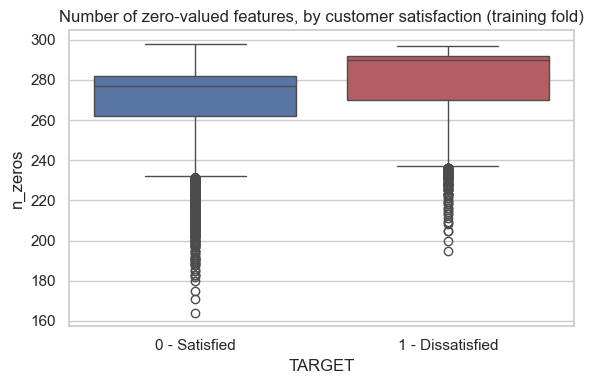

In [15]:
# Sanity check: does n_zeros actually differ between satisfied and dissatisfied customers?
# (Computed on the training fold only, consistent with everything else in this section.)
fig, ax = plt.subplots(figsize=(6, 4))
sns.boxplot(data=train_fe, x="TARGET", y="n_zeros", ax=ax, palette=["#4C72B0", "#C44E52"])
ax.set_xticklabels(["0 - Satisfied", "1 - Dissatisfied"])
ax.set_title("Number of zero-valued features, by customer satisfaction (training fold)")
plt.tight_layout()
plt.show()

If the two boxes above sit at clearly different heights, that is a good sign this engineered
feature carries a real signal. I let Section 7's statistical tests confirm this rigorously rather
than judging by eye alone.

## 7. Picking the variables that actually matter

I'm left with roughly 300 candidate columns (370 originals, minus the constant/duplicate ones,
plus the 2 I added). That's too many to look at one by one, and just throwing all of them into a
model isn't a great idea either - noisy or redundant columns slow training down, make models more
likely to overfit, and make it harder to trust the feature importances later.

**Everything in this section is computed from `train_fe` only** - `val_fe` doesn't get touched
anywhere below, for the reasons I explained in Section 5.

Instead of picking variables by one single rule, I ran **four different statistical techniques**
and only kept variables that several of them agreed on - like asking four different people for
their opinion and trusting whichever answer shows up most, rather than betting everything on one
person's take:

| # | Technique | What it captures | Blind spot |
|---|---|---|---|
| 1 | Correlation with `TARGET` | Straight-line (linear) relationships | Misses non-linear patterns |
| 2 | Mann-Whitney U test | Whether the whole distribution differs between the two classes, even if the relationship isn't linear | Doesn't rank *how strong* the effect is, just whether it's statistically significant |
| 3 | Mutual information | Any kind of statistical dependency, linear or not | Needs more data to be reliable; noisier estimate |
| 4 | Random Forest importance | How useful a variable is for splitting decisions inside real trees | Can be biased toward high-cardinality (many unique values) variables |

Before ranking anything, I also strip out **redundant** variables - pairs of columns that are
basically copies of each other. Otherwise one real signal that happens to show up in five
near-identical columns would get counted five separate times and crowd out other, genuinely
different variables.

### 7.1 Removing highly correlated (redundant) feature pairs

In [16]:
feature_candidates = [c for c in train_fe.columns if c not in ("ID", "TARGET")]
corr_matrix = train_fe[feature_candidates].corr().abs()

# I only need the upper triangle (correlation is symmetric, and a variable is always perfectly
# correlated with itself) to avoid flagging every pair twice.
upper_triangle = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

REDUNDANCY_THRESHOLD = 0.95
redundant_cols = [col for col in upper_triangle.columns if (upper_triangle[col] > REDUNDANCY_THRESHOLD).any()]

print(f"Found {len(redundant_cols)} columns that are >{REDUNDANCY_THRESHOLD:.0%} correlated with "
      f"another column already in the training fold.")

feature_candidates = [c for c in feature_candidates if c not in redundant_cols]
print(f"Feature candidates remaining after redundancy removal: {len(feature_candidates)}")

Found 95 columns that are >95% correlated with another column already in the training fold.
Feature candidates remaining after redundancy removal: 213


### 7.2 Correlation of each remaining variable with the target

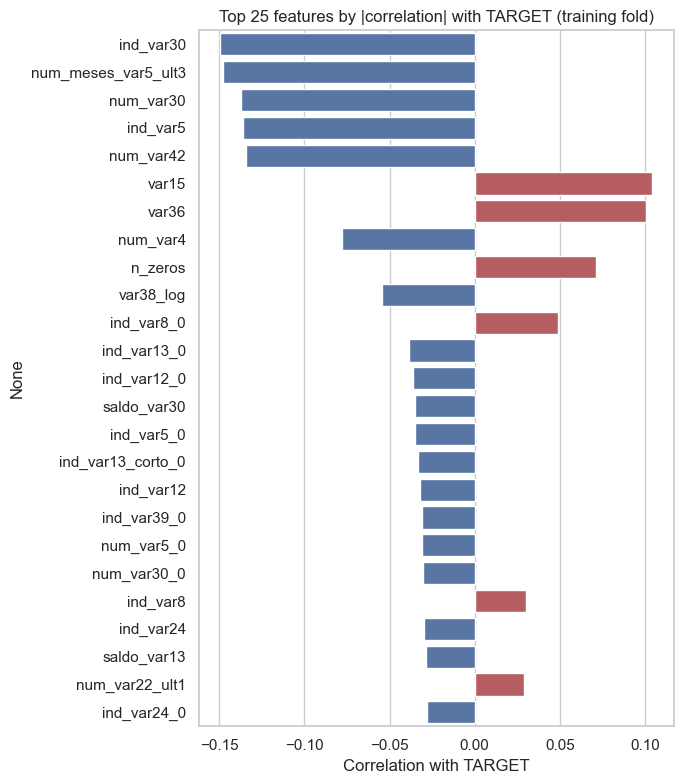

In [17]:
target_corr = train_fe[feature_candidates + ["TARGET"]].corr()["TARGET"].drop("TARGET")
target_corr_sorted = target_corr.reindex(target_corr.abs().sort_values(ascending=False).index)

top25_corr = target_corr_sorted.head(25)
fig, ax = plt.subplots(figsize=(7, 8))
colors = ["#C44E52" if v > 0 else "#4C72B0" for v in top25_corr.values]
sns.barplot(x=top25_corr.values, y=top25_corr.index, ax=ax, palette=colors)
ax.set_title("Top 25 features by |correlation| with TARGET (training fold)")
ax.set_xlabel("Correlation with TARGET")
plt.tight_layout()
plt.show()

**How to read this chart:** bars further from zero (in either direction) indicate a stronger
straight-line relationship with dissatisfaction. Red bars increase alongside `TARGET` (higher value
→ more likely dissatisfied); blue bars move the opposite way. These correlations tend to look
small in absolute terms (often under 0.2) — that is normal and expected for real-world human
behaviour data with a rare event like this one; no single anonymized banking variable is going to
perfectly predict dissatisfaction by itself. This is exactly why I combine several features and
several models rather than relying on one "magic variable".

### 7.3 Statistical significance: Mann-Whitney U test

Correlation only detects *linear* relationships. The Mann-Whitney U test instead asks a more
general question: **"if I randomly pick a satisfied customer and a dissatisfied customer, is one
of them systematically likely to have a higher value of this variable than the other?"** It makes
no assumption about the shape of the relationship, which suits these skewed, anonymized variables
well. A very small p-value (I use the common threshold 0.01) means the difference between the two
groups is very unlikely to be due to random chance alone.

In [18]:
satisfied = train_fe.loc[train_fe["TARGET"] == 0]
dissatisfied = train_fe.loc[train_fe["TARGET"] == 1]

p_values = {}
for col in feature_candidates:
    # Mann-Whitney U is a rank-based test: it doesn't care about the raw scale of the variable,
    # only about the relative ordering of values - this makes it robust to the extreme skew I
    # saw in variables like var38.
    try:
        _, p = stats.mannwhitneyu(satisfied[col], dissatisfied[col], alternative="two-sided")
    except ValueError:
        # Raised when a column has zero variance within one of the groups; treat as non-significant.
        p = 1.0
    p_values[col] = p

p_values = pd.Series(p_values).sort_values()
significant_cols = p_values[p_values < 0.01].index.tolist()

print(f"Features with a statistically significant difference between classes (p < 0.01): "
      f"{len(significant_cols)} out of {len(feature_candidates)}")

Features with a statistically significant difference between classes (p < 0.01): 84 out of 213


### 7.4 Mutual information

Mutual information measures how much knowing one variable reduces my uncertainty about another -
including non-linear and non-monotonic relationships that both the correlation coefficient and the
Mann-Whitney test can miss. It is more computationally expensive, so I run it once here on the
already-narrowed candidate list rather than on all 300+ raw columns.

In [19]:
mi_scores = mutual_info_classif(
    train_fe[feature_candidates], train_fe["TARGET"],
    discrete_features=False, random_state=RANDOM_STATE, n_neighbors=3
)
mi_scores = pd.Series(mi_scores, index=feature_candidates).sort_values(ascending=False)

mi_scores.head(20)

ind_var5                  0.022123
ind_var30                 0.020201
num_var42                 0.019690
num_meses_var5_ult3       0.016513
num_var30                 0.015976
num_var5_0                0.014535
num_var4                  0.013913
ind_var5_0                0.013139
saldo_var30               0.012879
var15                     0.012145
saldo_medio_var5_ult3     0.011639
n_zeros                   0.011569
num_var39_0               0.011296
saldo_medio_var5_ult1     0.011296
ind_var39_0               0.010996
var36                     0.010946
num_var30_0               0.010802
saldo_var5                0.010280
saldo_medio_var5_hace3    0.009677
num_var42_0               0.009542
dtype: float64

### 7.5 Random Forest importance

Finally, I train one moderately-sized Random Forest on the training fold's candidate features and
read off its built-in **feature importance**: how much, on average, each variable improved the
purity of the tree's splits. This captures interactions between variables that none of the
previous, single-variable techniques can see (e.g. "high value in variable A *combined with* low
value in variable B" might matter even if neither variable matters much on its own).

In [20]:
# A moderate number of shallow-ish trees is enough for a *ranking* of importance - I are not
# trying to build my final production model here, just to get an honest importance signal fast.
rf_ranker = RandomForestClassifier(
    n_estimators=200, max_depth=8, n_jobs=-1, random_state=RANDOM_STATE, class_weight="balanced"
)
rf_ranker.fit(train_fe[feature_candidates], train_fe["TARGET"])

rf_importance = pd.Series(rf_ranker.feature_importances_, index=feature_candidates).sort_values(ascending=False)
rf_importance.head(20)

var15                      0.186236
saldo_var30                0.071632
saldo_var5                 0.051694
saldo_medio_var5_ult3      0.049170
saldo_medio_var5_hace2     0.048624
ind_var30                  0.042030
saldo_medio_var5_ult1      0.040107
n_zeros                    0.038147
num_var30                  0.031606
saldo_medio_var5_hace3     0.030659
num_meses_var5_ult3        0.028825
num_var4                   0.028444
var38                      0.024350
ind_var5                   0.023505
var38_log                  0.022510
num_var42                  0.016129
num_var22_ult3             0.013835
imp_op_var41_efect_ult3    0.010192
num_var22_ult1             0.009785
var36                      0.009655
dtype: float64

### 7.6 Combining all four techniques into one final feature list

I convert each technique's result into a **rank** (1 = most important, according to that
technique) rather than comparing raw scores directly, because correlation, p-values, mutual
information and Gini importance live on completely different numeric scales and are not
comparable as-is. Ranks put all four techniques on the same footing. I then average the four
ranks per feature - a feature that several techniques agree is important will have a low (good)
average rank, while a feature only one technique likes will be pulled down by the other three.

In [21]:
scoreboard = pd.DataFrame(index=feature_candidates)
scoreboard["corr_rank"] = target_corr.abs().reindex(feature_candidates).rank(ascending=False)
scoreboard["mannwhitney_rank"] = p_values.reindex(feature_candidates).rank(ascending=True)
scoreboard["mutual_info_rank"] = mi_scores.reindex(feature_candidates).rank(ascending=False)
scoreboard["rf_importance_rank"] = rf_importance.reindex(feature_candidates).rank(ascending=False)

scoreboard["avg_rank"] = scoreboard.mean(axis=1)
scoreboard["is_statistically_significant"] = scoreboard.index.isin(significant_cols)
scoreboard = scoreboard.sort_values("avg_rank")

scoreboard.head(30)

,corr_rank,mannwhitney_rank,mutual_info_rank,rf_importance_rank,avg_rank,is_statistically_significant
ind_var30,1.0,1.0,2.0,6.0,2.500,True
num_var30,3.0,2.0,5.0,9.0,4.750,True
num_meses_var5_ult3,2.0,3.0,4.0,11.0,5.000,True
var15,6.0,5.0,10.0,1.0,5.500,True
ind_var5,4.0,6.0,1.0,14.0,6.250,True
num_var42,5.0,4.0,3.0,16.0,7.000,True
saldo_var30,14.0,7.0,9.0,2.0,8.000,True
num_var4,8.0,13.0,7.0,12.0,10.000,True
n_zeros,9.0,14.0,12.0,8.0,10.750,True
var36,7.0,15.0,16.0,20.0,14.500,True


In [22]:
# Final feature list: the top N features by average rank, restricted to those that also passed
# the Mann-Whitney significance test - i.e. features that several methods rate highly AND that I
# have statistical confidence are genuinely different between the two customer groups.
# All of it computed from train_fe only, per the fix explained in Section 5.
N_FEATURES = 30
candidate_pool = scoreboard[scoreboard["is_statistically_significant"]]
FINAL_FEATURES = candidate_pool.head(N_FEATURES).index.tolist()

print(f"Final feature set ({len(FINAL_FEATURES)} variables), chosen by training-fold-only "
      f"consensus across correlation, Mann-Whitney U test, mutual information and Random Forest "
      f"importance:\n")
print(FINAL_FEATURES)

Final feature set (30 variables), chosen by training-fold-only consensus across correlation, Mann-Whitney U test, mutual information and Random Forest importance:

['ind_var30', 'num_var30', 'num_meses_var5_ult3', 'var15', 'ind_var5', 'num_var42', 'saldo_var30', 'num_var4', 'n_zeros', 'var36', 'var38_log', 'saldo_medio_var5_ult3', 'num_var30_0', 'saldo_medio_var5_hace2', 'saldo_medio_var5_ult1', 'saldo_var5', 'saldo_var13', 'saldo_medio_var5_hace3', 'ind_var13_0', 'var38', 'saldo_var12', 'ind_var12_0', 'num_var5_0', 'num_var12_0', 'ind_var5_0', 'ind_var12', 'ind_var39_0', 'num_var39_0', 'saldo_medio_var13_corto_hace2', 'saldo_medio_var12_hace2']


### 7.7 Correlation heatmap of the final feature set

Now that I'm down to a manageable ~30 variables (plotting all ~300 at once would be an
unreadable wall of color), a correlation heatmap becomes genuinely useful: it lets me sanity-check
that I did not accidentally leave in near-duplicate variables, and it gives a first hint about
which groups of variables tend to move together. Shown for the training fold only.

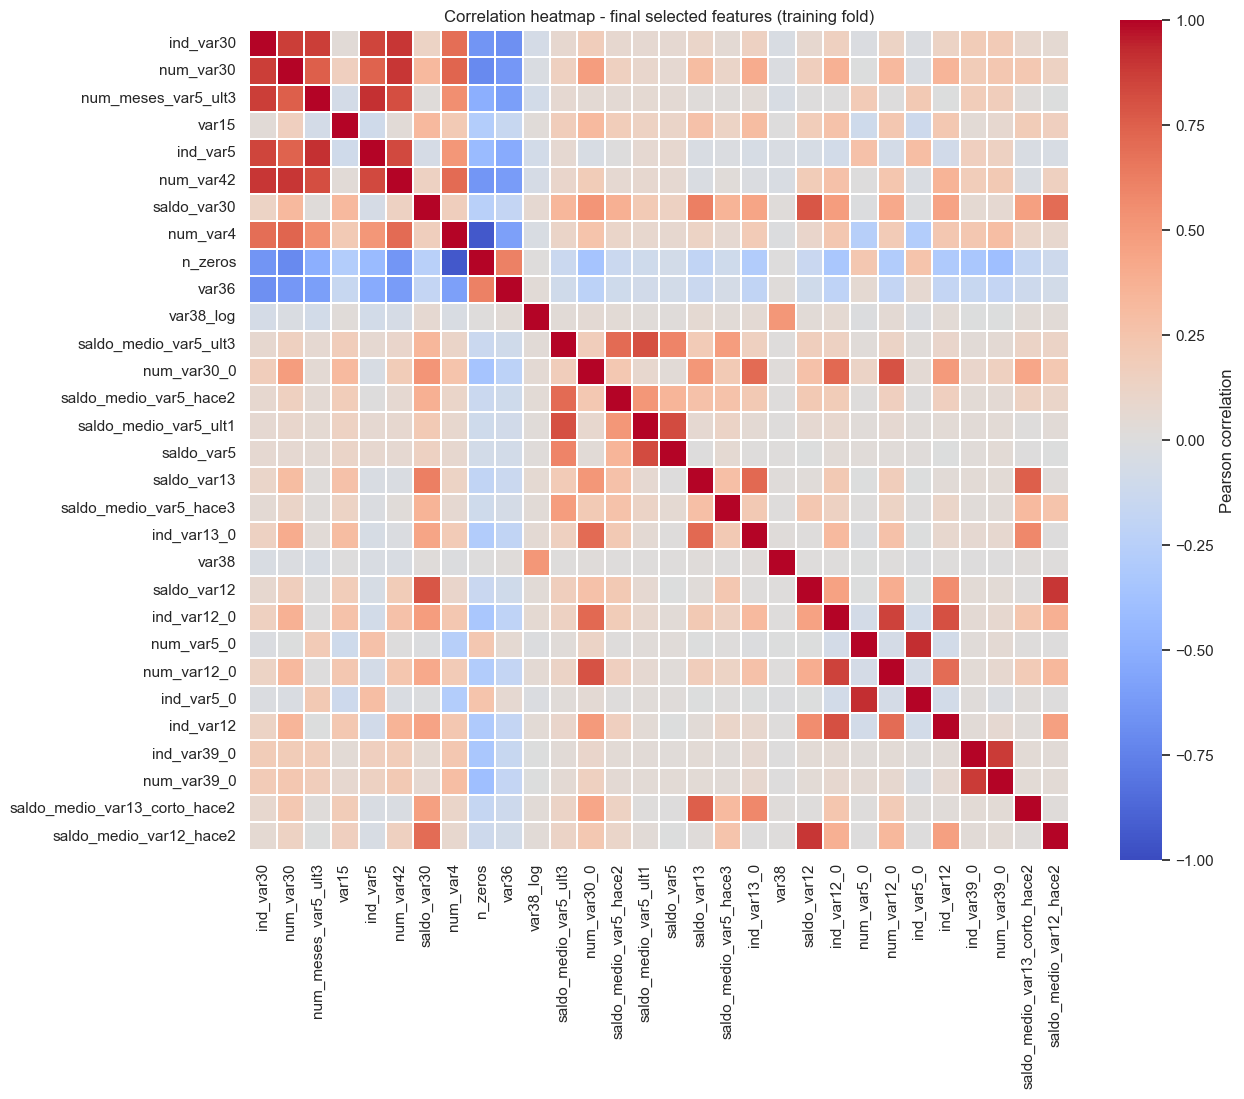

In [23]:
fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(
    train_fe[FINAL_FEATURES].corr(), cmap="coolwarm", center=0,
    vmin=-1, vmax=1, square=True, linewidths=0.3, ax=ax,
    cbar_kws={"label": "Pearson correlation"}
)
ax.set_title("Correlation heatmap - final selected features (training fold)")
plt.tight_layout()
plt.show()

In [24]:
X_train = train_fe[FINAL_FEATURES]
y_train = train_fe["TARGET"]
X_val = val_fe[FINAL_FEATURES]
y_val = val_fe["TARGET"]

print(f"X_train: {X_train.shape}   X_val: {X_val.shape}")

X_train: (57015, 30)   X_val: (19005, 30)


## 8. Getting ready for modeling: scaling and the class imbalance problem

Two more things need to happen before I start modeling, and the order I do them in actually
matters:

1. **Scaling** (`StandardScaler`): puts every feature on a comparable range (mean 0, standard
   deviation 1). This matters a lot for models that measure distance between customers (KNN, SVM)
   or that are sensitive to raw scale (Logistic Regression). Tree-based models barely care, but
   scaling everything the same way keeps the six-model comparison in Section 10 fair.
2. **SMOTE** (Synthetic Minority Over-sampling): since only ~4% of customers are dissatisfied, I
   generate synthetic examples of that minority class so models see something closer to a balanced
   mix during training, instead of just learning to predict "satisfied" every time. SMOTE builds a
   synthetic customer by taking a real dissatisfied customer, finding one of their nearest
   dissatisfied neighbors, and placing a new point somewhere between the two.

I start with SMOTE for the six-model comparison in Section 9 because it's the standard default and
gives every model the same fair baseline. But I don't just assume it's the right call and leave it
there - Section 12 tests SMOTE directly against a simpler alternative (class-weighting) and picks
whichever one actually performs better, based on real numbers.

> **One detail that's easy to get wrong:** scaling and SMOTE need to be recomputed from scratch
> inside every single cross-validation fold during hyperparameter tuning, using only that fold's
> training data - not done once, globally, before tuning even starts. Doing it globally would let
> synthetic points built from what *becomes* a validation fold sneak into that fold's "unseen"
> evaluation, which quietly inflates the score. I avoid this by bundling
> `StandardScaler -> SMOTE -> model` into one **imbalanced-learn Pipeline** and handing the whole
> pipeline to the hyperparameter search, so this happens correctly and automatically for every
> model below.

Before wrapping this in a pipeline, here's a small, purely illustrative preview of what SMOTE does
to the *shape* of the training fold (not used for modeling - just for intuition):

In [25]:
preview_scaler = StandardScaler().fit(X_train)
X_train_preview = preview_scaler.transform(X_train)
X_res_preview, y_res_preview = SMOTE(k_neighbors=5, random_state=RANDOM_STATE).fit_resample(X_train_preview, y_train)

print("Before SMOTE:\n", y_train.value_counts())
print("\nAfter SMOTE (illustration only):\n", pd.Series(y_res_preview).value_counts())

Before SMOTE:
 TARGET
0    54759
1     2256
Name: count, dtype: int64

After SMOTE (illustration only):
 TARGET
0    54759
1    54759
Name: count, dtype: int64


## 9. Training and comparing six models

Now for the actual modeling. I trained **six** different algorithms on the same features, the same
split, and the same evaluation approach, because that's the only fair way to answer the question
this whole notebook is really about: *which kind of model actually works best here?*

- **Logistic Regression** - my benchmark. Simple, fast, easy to interpret, and a good sanity check
  for whether anything fancier is actually worth its extra complexity.
- **Decision Tree** - a single tree of yes/no questions. Easy to visualize, but prone to
  overfitting on its own - which is exactly why Random Forest, below, trains a whole bunch of them.
- **K-Nearest Neighbours (KNN)** - classifies a customer by looking at the most similar customers
  in the training set and going with whatever the majority of them are.
- **Random Forest** - a team of many decision trees, each trained on a slightly different random
  slice of the data, with their votes averaged. Usually generalizes much better than any one tree.
- **Support Vector Machine (SVM)** - finds the boundary that separates the two classes with the
  widest possible margin. With the RBF kernel I used here, it can bend that boundary into
  non-linear shapes too.
- **Histogram-based Gradient Boosting** - builds trees one at a time, where each new tree focuses
  specifically on fixing the mistakes the previous ones made. This is the same family of idea
  behind popular libraries like XGBoost and LightGBM, and it's usually the strongest performer on
  tabular data like this. Scikit-learn's version is also built to be fast on datasets this size.

**A quick note on why I kept the search grids small:** tuning hyperparameters means training the
same model dozens of times with different settings, which adds up fast. To keep this runnable on a
normal laptop, I used `RandomizedSearchCV` (which samples a limited number of combinations instead
of trying every single one) with 3-fold cross-validation instead of the usual 5, and kept the
grids modest. **SVM** got extra treatment since it's by far the most expensive model here - I
trained it on a stratified subsample instead of the full data, and skipped `probability=True`
(which runs a slow extra internal cross-validation just to calibrate probabilities) in favor of
`decision_function`, which works just as well for ROC-AUC.

**One extra thing I tracked, for free:** alongside each model's validation score, I also kept the
**cross-validation mean and standard deviation** that `GridSearchCV`/`RandomizedSearchCV` already
computes while searching for the best hyperparameters. It costs nothing extra - it's just sitting
there in `cv_results_` - but it gives me a sense of how *stable* each model's score actually is,
which matters a lot in Section 10 when I check whether the ranking between models is trustworthy
or just noise from one particular split.

I collect every model's results in one table using a small `record_result()` helper below, instead
of copy-pasting the same bookkeeping six times.

In [26]:
results = []          # one dict per model, turned into a DataFrame at the end
roc_curves = {}       # store (fpr, tpr, auc) per model, for the combined ROC plot in Section 10
val_scores = {}        # store each model's raw validation scores, reused in Sections 11-13

# Computes and stores the standard set of metrics for one trained model.
# y_score is whatever ranking score the model produces (predicted probability, or SVM's
# decision_function) - it is what ROC-AUC actually needs, as opposed to the hard 0/1 prediction.
# cv_mean/cv_std (when available) come from the hyperparameter search's own cross-validation folds.
def record_result(name, algorithm, y_true, y_pred, y_score, cv_mean=None, cv_std=None):
    roc_auc = roc_auc_score(y_true, y_score)
    accuracy = accuracy_score(y_true, y_pred)
    fpr, tpr, _ = roc_curve(y_true, y_score)
    curve_auc = auc(fpr, tpr)

    roc_curves[name] = (fpr, tpr, curve_auc)
    val_scores[name] = y_score
    results.append({
        "Name": name,
        "Algorithm": algorithm,
        "Val_ROC_AUC": roc_auc,
        "Val_Accuracy": accuracy,
        "CV_ROC_AUC_mean": cv_mean,
        "CV_ROC_AUC_std": cv_std,
    })
    cv_str = f" | CV ROC-AUC = {cv_mean:.4f} +/- {cv_std:.4f}" if cv_mean is not None else ""
    print(f"[{name}] {algorithm}: Val ROC-AUC = {roc_auc:.4f} | Val Accuracy = {accuracy:.4f}{cv_str}")
    return roc_auc

### 9.1 Model 1 - Logistic Regression (benchmark)

In [27]:
pipe_logreg = ImbPipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(k_neighbors=2, random_state=RANDOM_STATE)),
    ("clf", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
])

grid_logreg = {
    "clf__C": [0.01, 0.1, 1, 10, 100],
    "clf__penalty": ["l2"],
}

search_logreg = GridSearchCV(pipe_logreg, grid_logreg, scoring="roc_auc", cv=3, n_jobs=-1)
search_logreg.fit(X_train, y_train)

print("Best hyperparameters:", search_logreg.best_params_)
model_v1 = search_logreg.best_estimator_

Best hyperparameters: {'clf__C': 10, 'clf__penalty': 'l2'}


[model_v1] Logistic Regression: Val ROC-AUC = 0.7946 | Val Accuracy = 0.6948 | CV ROC-AUC = 0.7902 +/- 0.0032


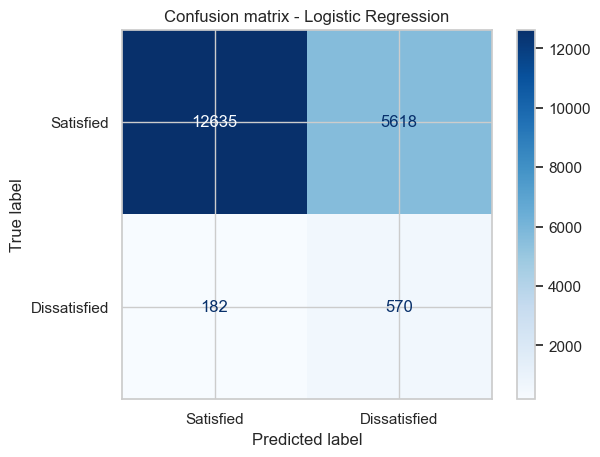

In [28]:
y_pred_v1 = model_v1.predict(X_val)
y_score_v1 = model_v1.predict_proba(X_val)[:, 1]
cv_mean_v1 = search_logreg.cv_results_["mean_test_score"][search_logreg.best_index_]
cv_std_v1 = search_logreg.cv_results_["std_test_score"][search_logreg.best_index_]
record_result("model_v1", "Logistic Regression", y_val, y_pred_v1, y_score_v1, cv_mean_v1, cv_std_v1)

ConfusionMatrixDisplay.from_predictions(y_val, y_pred_v1, display_labels=["Satisfied", "Dissatisfied"], cmap="Blues")
plt.title("Confusion matrix - Logistic Regression")
plt.show()

In [29]:
joblib.dump(model_v1, os.path.join(MODEL_DIR, "model_v1_logreg.pkl"))
print("Saved model_v1 to disk.")

Saved model_v1 to disk.


### 9.2 Model 2 - Decision Tree

In [30]:
pipe_tree = ImbPipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(k_neighbors=2, random_state=RANDOM_STATE)),
    ("clf", DecisionTreeClassifier(random_state=RANDOM_STATE)),
])

grid_tree = {
    "clf__max_depth": [3, 4, 5, 6, 7],
    "clf__min_samples_split": [2, 5, 10],
    "clf__min_samples_leaf": [1, 2, 4, 8],
}

search_tree = RandomizedSearchCV(
    pipe_tree, grid_tree, n_iter=15, scoring="roc_auc", cv=3, n_jobs=-1, random_state=RANDOM_STATE
)
search_tree.fit(X_train, y_train)

print("Best hyperparameters:", search_tree.best_params_)
model_v2 = search_tree.best_estimator_

Best hyperparameters: {'clf__min_samples_split': 5, 'clf__min_samples_leaf': 4, 'clf__max_depth': 5}


In [31]:
y_pred_v2 = model_v2.predict(X_val)
y_score_v2 = model_v2.predict_proba(X_val)[:, 1]
cv_mean_v2 = search_tree.cv_results_["mean_test_score"][search_tree.best_index_]
cv_std_v2 = search_tree.cv_results_["std_test_score"][search_tree.best_index_]
record_result("model_v2", "Decision Tree", y_val, y_pred_v2, y_score_v2, cv_mean_v2, cv_std_v2)
joblib.dump(model_v2, os.path.join(MODEL_DIR, "model_v2_decisiontree.pkl"))

[model_v2] Decision Tree: Val ROC-AUC = 0.8165 | Val Accuracy = 0.7777 | CV ROC-AUC = 0.8040 +/- 0.0062


['models\\model_v2_decisiontree.pkl']

### 9.3 Model 3 - K-Nearest Neighbours

KNN has no hyperparameters to "train" in the usual sense - its only real setting is `k`, the number
of neighbours to consult. I pick `k` using cross-validated ROC-AUC over a small range of odd
values (odd, so that majority votes can't tie).

In [32]:
neighbor_options = list(range(3, 20, 4))   # fewer candidates than a dense odd-number sweep -
                                            # keeps this loop's cost reasonable given KNN is
                                            # re-fit from scratch for every k x every CV fold
knn_cv_means, knn_cv_stds = [], []
for k in neighbor_options:
    pipe_knn_k = ImbPipeline([
        ("scaler", StandardScaler()),
        ("smote", SMOTE(k_neighbors=2, random_state=RANDOM_STATE)),
        ("clf", KNeighborsClassifier(n_neighbors=k, n_jobs=-1)),
    ])
    scores = cross_val_score(pipe_knn_k, X_train, y_train, cv=3, scoring="roc_auc")
    knn_cv_means.append(scores.mean())
    knn_cv_stds.append(scores.std())
    print(f"k={k:>2}  mean CV ROC-AUC = {scores.mean():.4f} +/- {scores.std():.4f}")

best_idx = int(np.argmax(knn_cv_means))
optimal_k = neighbor_options[best_idx]
cv_mean_v3, cv_std_v3 = knn_cv_means[best_idx], knn_cv_stds[best_idx]
print(f"\nBest k: {optimal_k}")

k= 3  mean CV ROC-AUC = 0.6149 +/- 0.0014


k= 7  mean CV ROC-AUC = 0.6707 +/- 0.0083


k=11  mean CV ROC-AUC = 0.6924 +/- 0.0072


k=15  mean CV ROC-AUC = 0.7072 +/- 0.0072


k=19  mean CV ROC-AUC = 0.7204 +/- 0.0041

Best k: 19


In [33]:
pipe_knn = ImbPipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(k_neighbors=2, random_state=RANDOM_STATE)),
    ("clf", KNeighborsClassifier(n_neighbors=optimal_k, n_jobs=-1)),
])
pipe_knn.fit(X_train, y_train)
model_v3 = pipe_knn

y_pred_v3 = model_v3.predict(X_val)
y_score_v3 = model_v3.predict_proba(X_val)[:, 1]
record_result("model_v3", "KNN", y_val, y_pred_v3, y_score_v3, cv_mean_v3, cv_std_v3)
joblib.dump(model_v3, os.path.join(MODEL_DIR, "model_v3_knn.pkl"))

[model_v3] KNN: Val ROC-AUC = 0.7408 | Val Accuracy = 0.7666 | CV ROC-AUC = 0.7204 +/- 0.0041


['models\\model_v3_knn.pkl']

### 9.4 Model 4 - Random Forest

In [34]:
pipe_rf = ImbPipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(k_neighbors=2, random_state=RANDOM_STATE)),
    ("clf", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)),
])

grid_rf = {
    "clf__n_estimators": [200, 300, 400],
    "clf__max_depth": [6, 8, 10, None],
    "clf__min_samples_split": [2, 5, 10],
    "clf__min_samples_leaf": [1, 2, 4],
}

search_rf = RandomizedSearchCV(
    pipe_rf, grid_rf, n_iter=12, scoring="roc_auc", cv=3, n_jobs=-1, random_state=RANDOM_STATE
)
search_rf.fit(X_train, y_train)

print("Best hyperparameters:", search_rf.best_params_)
model_v4 = search_rf.best_estimator_

Best hyperparameters: {'clf__n_estimators': 200, 'clf__min_samples_split': 5, 'clf__min_samples_leaf': 1, 'clf__max_depth': 8}


In [35]:
y_pred_v4 = model_v4.predict(X_val)
y_score_v4 = model_v4.predict_proba(X_val)[:, 1]
cv_mean_v4 = search_rf.cv_results_["mean_test_score"][search_rf.best_index_]
cv_std_v4 = search_rf.cv_results_["std_test_score"][search_rf.best_index_]
record_result("model_v4", "Random Forest", y_val, y_pred_v4, y_score_v4, cv_mean_v4, cv_std_v4)
joblib.dump(model_v4, os.path.join(MODEL_DIR, "model_v4_randomforest.pkl"))

[model_v4] Random Forest: Val ROC-AUC = 0.8267 | Val Accuracy = 0.7875 | CV ROC-AUC = 0.8216 +/- 0.0028


['models\\model_v4_randomforest.pkl']

### 9.5 Model 5 - Support Vector Machine (SVM)

As discussed above, this is the most computationally expensive model in the comparison, so I
deliberately keep its search small (`n_iter=6`, `cv=3`) and skip `probability=True`, using
`decision_function` for ranking-based metrics instead.

**One more cost-control decision specific to SVM:** the RBF kernel's training time grows roughly
quadratically-to-cubically with the number of rows. Fitting it 18 times (6 candidate hyperparameter
combinations x 3 CV folds) on my ~57,000-row training fold - which SMOTE then roughly doubles -
would be dramatically slower than every other model here, without a proportional benefit for what
is meant to be a *comparison* baseline. I therefore tune and fit SVM on a **stratified random
subsample** of the training fold (kept at the same ~96/4 class ratio). This is a standard,
explicitly-documented trade-off when including kernel SVMs in a benchmark over tens of thousands of
rows: I accept a slightly noisier estimate of SVM's best hyperparameters and final performance, in
exchange for keeping the whole notebook practical to run end-to-end. The other five models are
trained on the full training fold.

In [36]:
SVM_SAMPLE_SIZE = 8000
X_train_svm, _, y_train_svm, _ = train_test_split(
    X_train, y_train, train_size=SVM_SAMPLE_SIZE, stratify=y_train, random_state=RANDOM_STATE
)
print(f"SVM training subsample: {X_train_svm.shape[0]:,} rows "
      f"(class balance: {y_train_svm.value_counts(normalize=True).round(4).to_dict()})")

pipe_svm = ImbPipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(k_neighbors=2, random_state=RANDOM_STATE)),
    ("clf", SVC(kernel="rbf", random_state=RANDOM_STATE)),
])

grid_svm = {
    "clf__C": [0.1, 1, 10],
    "clf__gamma": ["scale", 0.01, 0.1],
}

search_svm = RandomizedSearchCV(
    pipe_svm, grid_svm, n_iter=6, scoring="roc_auc", cv=3, n_jobs=-1, random_state=RANDOM_STATE
)
search_svm.fit(X_train_svm, y_train_svm)

print("Best hyperparameters:", search_svm.best_params_)
model_v5 = search_svm.best_estimator_

SVM training subsample: 8,000 rows (class balance: {0: 0.9604, 1: 0.0396})


Best hyperparameters: {'clf__gamma': 'scale', 'clf__C': 0.1}


In [37]:
y_pred_v5 = model_v5.predict(X_val)
y_score_v5 = model_v5.decision_function(X_val)   # SVM's native ranking score - no expensive
                                                  # probability calibration needed for ROC-AUC
cv_mean_v5 = search_svm.cv_results_["mean_test_score"][search_svm.best_index_]
cv_std_v5 = search_svm.cv_results_["std_test_score"][search_svm.best_index_]
record_result("model_v5", "SVM (RBF)", y_val, y_pred_v5, y_score_v5, cv_mean_v5, cv_std_v5)
joblib.dump(model_v5, os.path.join(MODEL_DIR, "model_v5_svm.pkl"))

[model_v5] SVM (RBF): Val ROC-AUC = 0.7950 | Val Accuracy = 0.7084 | CV ROC-AUC = 0.7990 +/- 0.0227


['models\\model_v5_svm.pkl']

### 9.6 Model 6 - Histogram-based Gradient Boosting

Gradient boosting is generally the strongest family of algorithms for structured/tabular data like
this dataset, and scikit-learn's histogram-based implementation is specifically built for speed on
larger datasets (it bins continuous features into a small number of buckets before finding tree
splits, dramatically cutting search cost compared to a naive gradient boosting implementation).

In [38]:
pipe_hgb = ImbPipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(k_neighbors=2, random_state=RANDOM_STATE)),
    ("clf", HistGradientBoostingClassifier(random_state=RANDOM_STATE)),
])

grid_hgb = {
    "clf__max_iter": [100, 200, 300],
    "clf__max_depth": [3, 5, 7, None],
    "clf__learning_rate": [0.03, 0.06, 0.1],
    "clf__l2_regularization": [0.0, 0.1, 1.0],
}

search_hgb = RandomizedSearchCV(
    pipe_hgb, grid_hgb, n_iter=12, scoring="roc_auc", cv=3, n_jobs=-1, random_state=RANDOM_STATE
)
search_hgb.fit(X_train, y_train)

print("Best hyperparameters:", search_hgb.best_params_)
model_v6 = search_hgb.best_estimator_

Best hyperparameters: {'clf__max_iter': 200, 'clf__max_depth': 5, 'clf__learning_rate': 0.03, 'clf__l2_regularization': 0.0}


In [39]:
y_pred_v6 = model_v6.predict(X_val)
y_score_v6 = model_v6.predict_proba(X_val)[:, 1]
cv_mean_v6 = search_hgb.cv_results_["mean_test_score"][search_hgb.best_index_]
cv_std_v6 = search_hgb.cv_results_["std_test_score"][search_hgb.best_index_]
record_result("model_v6", "Hist Gradient Boosting", y_val, y_pred_v6, y_score_v6, cv_mean_v6, cv_std_v6)
joblib.dump(model_v6, os.path.join(MODEL_DIR, "model_v6_histgb.pkl"))

[model_v6] Hist Gradient Boosting: Val ROC-AUC = 0.8319 | Val Accuracy = 0.8209 | CV ROC-AUC = 0.8211 +/- 0.0037


['models\\model_v6_histgb.pkl']

## 10. Comparing all six models - with cross-validated confidence, not a single lucky split

I use **ROC-AUC** (not accuracy) as the deciding metric, for the reasons explained in Section 0
and Section 3.1. The table below shows both the single-split validation score (`Val_ROC_AUC`) and
the cross-validation range from the hyperparameter search (`CV_ROC_AUC_mean` +/- `CV_ROC_AUC_std`)
side by side, precisely so I can sanity-check one against the other before trusting a ranking.

In [40]:
results_df = pd.DataFrame(results).sort_values("Val_ROC_AUC", ascending=False).reset_index(drop=True)
results_df

,Name,Algorithm,Val_ROC_AUC,Val_Accuracy,CV_ROC_AUC_mean,CV_ROC_AUC_std
0,model_v6,Hist Gradient Boosting,0.831886,0.820889,0.821104,0.003716
1,model_v4,Random Forest,0.826749,0.787530,0.821552,0.002821
2,model_v2,Decision Tree,0.816550,0.777743,0.803972,0.006161
3,model_v5,SVM (RBF),0.794961,0.708445,0.798980,0.022680
4,model_v1,Logistic Regression,0.794623,0.694817,0.790155,0.003153
5,model_v3,KNN,0.740769,0.766640,0.720380,0.004123


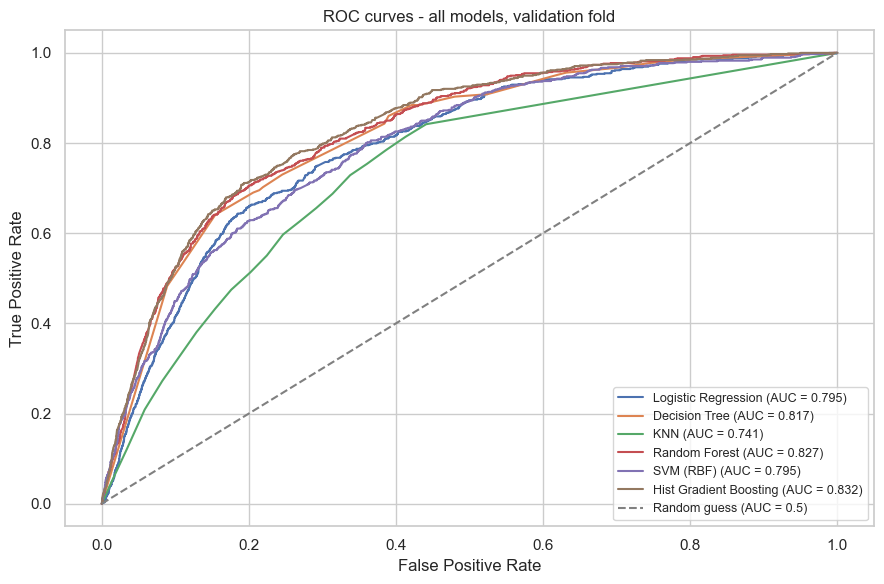

In [41]:
fig, ax = plt.subplots(figsize=(9, 6))
for name, (fpr, tpr, curve_auc) in roc_curves.items():
    algo = results_df.loc[results_df["Name"] == name, "Algorithm"].values[0]
    ax.plot(fpr, tpr, label=f"{algo} (AUC = {curve_auc:.3f})")

ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guess (AUC = 0.5)")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC curves - all models, validation fold")
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

**How to read this chart:** the closer a curve hugs the top-left corner, the better that model
separates dissatisfied customers from satisfied ones across every possible decision threshold. The
dashed diagonal line is what a model with no predictive power at all would produce (equivalent to
randomly guessing).

**How to read the CV columns in the table above, and why they matter:** the top few models in
`Val_ROC_AUC` are often close together - sometimes closer than one `CV_ROC_AUC_std` apart. When
that happens, I should treat the ranking between them as **uncertain**, not settled, no matter how
confidently a single validation number seems to declare a winner. Section 11 checks this directly
for the top two models, instead of just eyeballing the standard deviations.

## 11. Is the top model *really* better than the runner-up?

The comparison table in Section 10 has a winner by a few thousandths of ROC-AUC - but is that a
real, reproducible difference, or could it just as easily have gone the other way with a slightly
different validation split? I answer this with the **bootstrap**: a technique that re-uses the
predictions I already have (no retraining needed - cheap) to build an empirical picture of how
much the AUC difference between two models would wobble if I had drawn a slightly different
validation set from the same population.

**How it works, in plain terms:** I have `N` validation customers with two sets of predicted
scores (one per model) and their true outcomes. I repeatedly build a "fake" validation set of the
same size by sampling customers **with replacement** from the real one (so some customers appear
twice, others zero times, in any given resample) - this simulates "what if I had gotten a
slightly different, but equally valid, batch of validation customers?" I compute both models' AUC
on each resample and track the difference. Doing this thousands of times gives me a distribution of
plausible AUC differences, from which I read off a 95% confidence interval and how often the
current "winner" actually wins.

In [42]:
top_two = results_df.head(2)["Name"].tolist()
name_a, name_b = top_two[0], top_two[1]
algo_a = results_df.loc[results_df["Name"] == name_a, "Algorithm"].values[0]
algo_b = results_df.loc[results_df["Name"] == name_b, "Algorithm"].values[0]

scores_a = np.asarray(val_scores[name_a])
scores_b = np.asarray(val_scores[name_b])
y_val_arr = np.asarray(y_val)

N_BOOTSTRAP = 2000
rng = np.random.RandomState(RANDOM_STATE)
n = len(y_val_arr)
auc_diffs = np.empty(N_BOOTSTRAP)

for i in range(N_BOOTSTRAP):
    idx = rng.randint(0, n, n)          # sample n indices, with replacement
    y_boot = y_val_arr[idx]
    # A resample can occasionally end up with only one class present (rare, but possible with a
    # ~4% minority class) - roc_auc_score is undefined there, so I just redraw in that case.
    while y_boot.min() == y_boot.max():
        idx = rng.randint(0, n, n)
        y_boot = y_val_arr[idx]
    auc_a = roc_auc_score(y_boot, scores_a[idx])
    auc_b = roc_auc_score(y_boot, scores_b[idx])
    auc_diffs[i] = auc_a - auc_b

ci_low, ci_high = np.percentile(auc_diffs, [2.5, 97.5])
win_rate = (auc_diffs > 0).mean()

print(f"Comparing {algo_a} ({name_a}) vs. {algo_b} ({name_b})")
print(f"Observed validation AUC difference: {results_df.iloc[0]['Val_ROC_AUC'] - results_df.iloc[1]['Val_ROC_AUC']:.4f}")
print(f"Bootstrap 95% CI for the AUC difference: [{ci_low:.4f}, {ci_high:.4f}]")
print(f"{algo_a} beats {algo_b} in {win_rate:.1%} of the {N_BOOTSTRAP} bootstrap resamples")

Comparing Hist Gradient Boosting (model_v6) vs. Random Forest (model_v4)
Observed validation AUC difference: 0.0051
Bootstrap 95% CI for the AUC difference: [-0.0001, 0.0105]
Hist Gradient Boosting beats Random Forest in 97.3% of the 2000 bootstrap resamples


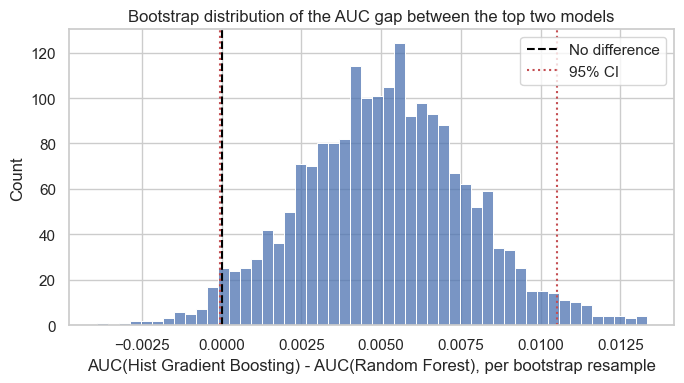

In [43]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(auc_diffs, bins=50, color="#4C72B0", ax=ax)
ax.axvline(0, color="black", linestyle="--", label="No difference")
ax.axvline(ci_low, color="#C44E52", linestyle=":", label="95% CI")
ax.axvline(ci_high, color="#C44E52", linestyle=":")
ax.set_xlabel(f"AUC({algo_a}) - AUC({algo_b}), per bootstrap resample")
ax.set_title("Bootstrap distribution of the AUC gap between the top two models")
ax.legend()
plt.tight_layout()
plt.show()

**How to read this:** if the 95% confidence interval above **excludes 0**, the top model's
advantage is unlikely to be a fluke of this particular validation split - I can reasonably trust
the ranking from Section 10. If the interval **includes 0** (i.e., the shaded histogram straddles
the dashed "no difference" line), the two models are statistically indistinguishable on this data,
and picking between them on validation AUC alone would be over-trusting a small, noisy difference -
in that case, other considerations (training/inference speed, interpretability, robustness) are
just as valid a tie-breaker as the leaderboard number.

In [44]:
# Looked up by name throughout the rest of the notebook, so everything downstream works
# automatically no matter which model actually won Section 10.
fitted_models = {
    "model_v1": model_v1, "model_v2": model_v2, "model_v3": model_v3,
    "model_v4": model_v4, "model_v5": model_v5, "model_v6": model_v6,
}
best_row = results_df.iloc[0]
best_model_name = best_row["Name"]
best_model_algorithm = best_row["Algorithm"]
best_model = fitted_models[best_model_name]

print(f"Current leaderboard winner: {best_model_name} ({best_model_algorithm})")

Current leaderboard winner: model_v6 (Hist Gradient Boosting)


## 12. SMOTE vs. class-weighting: which imbalance strategy should I actually ship?

Every model above was trained with SMOTE, mostly because it is the most common default choice and
gave me one consistent setup for a fair six-way comparison. But SMOTE has a real, specific cost
that is easy to overlook: **it changes what the model's predicted probabilities mean.**

**Why this matters, in plain terms:** SMOTE creates a training set that is artificially ~50%
dissatisfied. A model trained on that mix learns to output probabilities calibrated to a 50/50
world - not the real ~96/4 world these customers actually come from. Its predicted "probability of
dissatisfaction" will typically run systematically **too high**. For a Kaggle leaderboard, this
barely matters (only the *ranking* of scores is graded). For a bank that wants to say "I believe
this specific customer has a 30% chance of leaving," it matters a great deal.

**The alternative I test here is `class_weight="balanced"`**: instead of manufacturing synthetic
customers, I simply tell the classifier to pay `~24x` more attention to each dissatisfied customer
during training (the exact ratio the real class imbalance calls for) - no new points are created,
and the model still sees the real, natural mix of customers, which tends to produce more honest
probabilities.

I test this directly, rather than assuming either answer, on the **current leaderboard winner**
from Section 10 - reusing its already-tuned hyperparameters (no new hyperparameter search needed,
so this costs very little extra compute) and comparing three variants:

1. **SMOTE** (what I've used so far)
2. **`class_weight="balanced"`**, no resampling
3. **No imbalance handling at all** (a reference point, to see how much either strategy actually helps)

I judge them on two different questions, because they are not the same question:

- **Val ROC-AUC** - can the model still *rank* customers correctly?
- **Brier score** - a standard measure of probability calibration (mean squared error between
  predicted probability and the actual 0/1 outcome; **lower is better**, 0 is perfect). I back this
  up with a **calibration curve** (reliability diagram): customers are grouped into bins by their
  predicted probability, and for each bin I plot the *average predicted* probability against the
  *actual observed* fraction of dissatisfied customers in that bin. A perfectly calibrated model
  traces the diagonal line.

In [45]:
from sklearn.base import clone

winner_pipeline = best_model
winner_clf = winner_pipeline.named_steps["clf"]
clf_supports_class_weight = "class_weight" in winner_clf.get_params()

print(f"Running the imbalance-strategy ablation on: {best_model_algorithm} ({best_model_name})")
print(f"Supports class_weight natively: {clf_supports_class_weight}")

Running the imbalance-strategy ablation on: Hist Gradient Boosting (model_v6)
Supports class_weight natively: True


In [46]:
calibration_variants = {}    # strategy name -> validation scores
calibration_pipelines = {}   # strategy name -> fitted pipeline (reused in Sections 13-15)

# Variant 1: SMOTE - this is just the already-fitted winning pipeline, no retraining needed.
score_smote = winner_pipeline.predict_proba(X_val)[:, 1] if hasattr(winner_pipeline, "predict_proba") \
    else winner_pipeline.decision_function(X_val)
calibration_variants["SMOTE"] = score_smote
calibration_pipelines["SMOTE"] = winner_pipeline

if clf_supports_class_weight:
    # Variant 2: class_weight="balanced", no resampling - clone the winner's tuned classifier
    # settings so this is an apples-to-apples comparison of *only* the imbalance strategy.
    clf_balanced = clone(winner_clf).set_params(class_weight="balanced")
    pipe_balanced = ImbPipeline([("scaler", StandardScaler()), ("clf", clf_balanced)])
    pipe_balanced.fit(X_train, y_train)
    score_balanced = pipe_balanced.predict_proba(X_val)[:, 1] if hasattr(pipe_balanced, "predict_proba") \
        else pipe_balanced.decision_function(X_val)
    calibration_variants["class_weight=balanced"] = score_balanced
    calibration_pipelines["class_weight=balanced"] = pipe_balanced

    # Variant 3: no imbalance handling at all - a reference point.
    clf_plain = clone(winner_clf).set_params(class_weight=None)
    pipe_plain = ImbPipeline([("scaler", StandardScaler()), ("clf", clf_plain)])
    pipe_plain.fit(X_train, y_train)
    score_plain = pipe_plain.predict_proba(X_val)[:, 1] if hasattr(pipe_plain, "predict_proba") \
        else pipe_plain.decision_function(X_val)
    calibration_variants["No rebalancing"] = score_plain
    calibration_pipelines["No rebalancing"] = pipe_plain
else:
    print(f"{best_model_algorithm} has no class_weight parameter - comparing SMOTE against a "
          f"plain (unweighted, unresampled) fit only.")
    clf_plain = clone(winner_clf)
    pipe_plain = ImbPipeline([("scaler", StandardScaler()), ("clf", clf_plain)])
    pipe_plain.fit(X_train, y_train)
    score_plain = pipe_plain.predict_proba(X_val)[:, 1] if hasattr(pipe_plain, "predict_proba") \
        else pipe_plain.decision_function(X_val)
    calibration_variants["No rebalancing"] = score_plain
    calibration_pipelines["No rebalancing"] = pipe_plain

ablation_rows = []
for variant_name, y_score in calibration_variants.items():
    # Brier score needs a genuine probability in [0, 1] - decision_function scores (SVM) aren't
    # one, so I min-max rescale them purely for this calibration comparison.
    score_01 = y_score if y_score.min() >= 0 and y_score.max() <= 1 else \
        (y_score - y_score.min()) / (y_score.max() - y_score.min())
    ablation_rows.append({
        "Strategy": variant_name,
        "Val_ROC_AUC": roc_auc_score(y_val, y_score),
        "Brier_score": brier_score_loss(y_val, score_01),
    })

ablation_df = pd.DataFrame(ablation_rows).sort_values("Brier_score")
ablation_df

,Strategy,Val_ROC_AUC,Brier_score
2,No rebalancing,0.836352,0.034781
0,SMOTE,0.831886,0.130916
1,class_weight=balanced,0.837826,0.160861


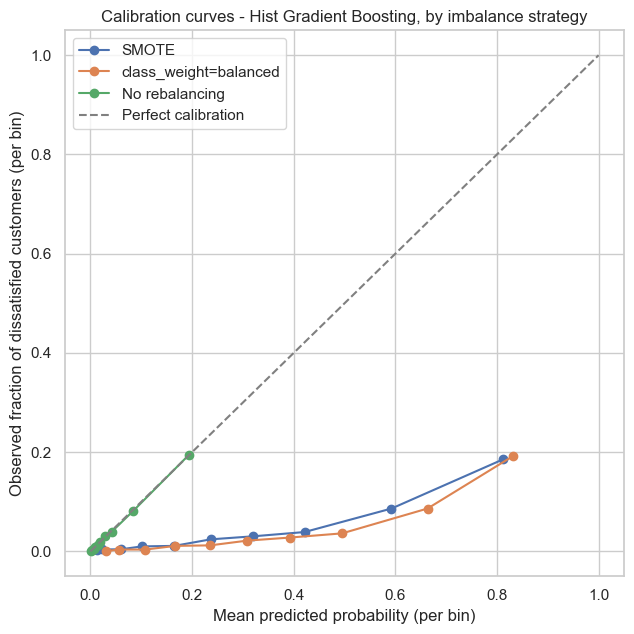

In [47]:
fig, ax = plt.subplots(figsize=(6.5, 6.5))
for variant_name, y_score in calibration_variants.items():
    score_01 = y_score if y_score.min() >= 0 and y_score.max() <= 1 else \
        (y_score - y_score.min()) / (y_score.max() - y_score.min())
    frac_pos, mean_pred = calibration_curve(y_val, score_01, n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", label=variant_name)

ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Perfect calibration")
ax.set_xlabel("Mean predicted probability (per bin)")
ax.set_ylabel("Observed fraction of dissatisfied customers (per bin)")
ax.set_title(f"Calibration curves - {best_model_algorithm}, by imbalance strategy")
ax.legend()
plt.tight_layout()
plt.show()

**How to read this chart:** a curve sitting **above** the diagonal means the model *underestimates*
risk in that probability range; a curve sitting **below** the diagonal means it *overestimates*
risk - which is exactly the distortion I expected SMOTE to introduce. The closer a line hugs the
diagonal, the more its predicted probabilities can be trusted at face value.

In [48]:
# The actual decision: I don't want to sacrifice much ranking ability (Val_ROC_AUC) just to chase
# better-calibrated probabilities, but if a variant is both no worse than SMOTE within a small
# tolerance AND noticeably better calibrated (lower Brier score), that is a strictly better choice
# to ship - better decisions AND more trustworthy probabilities, at no real cost.
AUC_TOLERANCE = 0.005
smote_row = ablation_df.loc[ablation_df["Strategy"] == "SMOTE"].iloc[0]

FINAL_BALANCING_STRATEGY = "SMOTE"
best_alt = ablation_df.loc[ablation_df["Strategy"] != "SMOTE"].sort_values("Brier_score").iloc[0] \
    if (ablation_df["Strategy"] != "SMOTE").any() else None

if best_alt is not None and \
        best_alt["Brier_score"] < smote_row["Brier_score"] and \
        best_alt["Val_ROC_AUC"] >= smote_row["Val_ROC_AUC"] - AUC_TOLERANCE:
    FINAL_BALANCING_STRATEGY = best_alt["Strategy"]

print(f"SMOTE  -> Val ROC-AUC = {smote_row['Val_ROC_AUC']:.4f} | Brier = {smote_row['Brier_score']:.4f}")
if best_alt is not None:
    print(f"{best_alt['Strategy']:<22} -> Val ROC-AUC = {best_alt['Val_ROC_AUC']:.4f} | "
          f"Brier = {best_alt['Brier_score']:.4f}")

print(f"\nDecision: the model I ship (Section 15) will use -> {FINAL_BALANCING_STRATEGY}")
if FINAL_BALANCING_STRATEGY != "SMOTE":
    print("Reason: comparable-or-better ranking (within tolerance) AND meaningfully better-"
          "calibrated probabilities than SMOTE.")
else:
    print("Reason: no alternative beat SMOTE on calibration without giving up ranking "
          "performance beyond my tolerance, so SMOTE remains the better choice here.")

SMOTE  -> Val ROC-AUC = 0.8319 | Brier = 0.1309
No rebalancing         -> Val ROC-AUC = 0.8364 | Brier = 0.0348

Decision: the model I ship (Section 15) will use -> No rebalancing
Reason: comparable-or-better ranking (within tolerance) AND meaningfully better-calibrated probabilities than SMOTE.


In [49]:
# The pipeline and scores I carry forward into every remaining section - whichever imbalance
# strategy actually won the empirical test above, not necessarily the one I started with.
final_eval_pipeline = calibration_pipelines[FINAL_BALANCING_STRATEGY]
final_eval_scores = calibration_variants[FINAL_BALANCING_STRATEGY]

print(f"Sections 13-14 evaluate: {best_model_algorithm} trained with {FINAL_BALANCING_STRATEGY}")

Sections 13-14 evaluate: Hist Gradient Boosting trained with No rebalancing


## 13. Precision-Recall analysis and "who do I call first?"

ROC-AUC treats false positives among the *huge* satisfied majority as cheap, because the false
positive **rate** has ~73,000 satisfied customers in its denominator - a handful of extra false
alarms barely moves it. That is mathematically correct but can make a model look better than it
would feel operationally, when the bank has to actually act on these scores. The
**Precision-Recall curve** is a more honest lens for a rare event like this one: it directly plots,
at every possible decision threshold, what fraction of the customers I *flag* are truly
dissatisfied (**precision**) against what fraction of *all* dissatisfied customers I actually
catch (**recall**).

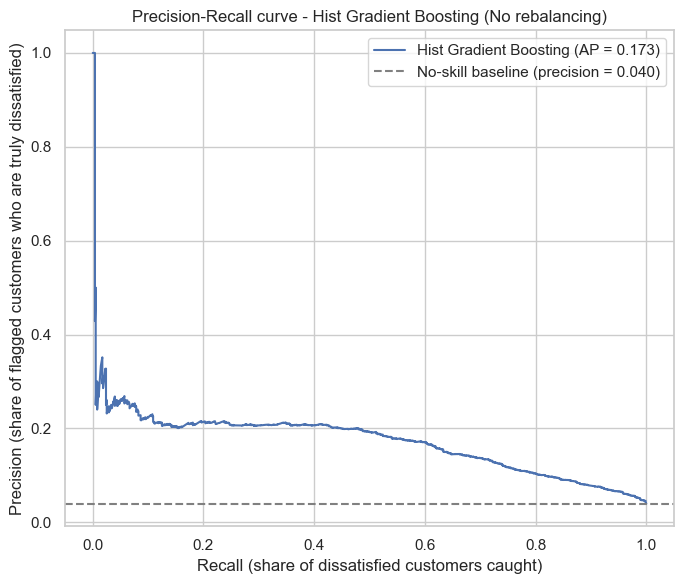

In [50]:
precision, recall, pr_thresholds = precision_recall_curve(y_val, final_eval_scores)
avg_precision = average_precision_score(y_val, final_eval_scores)
baseline_precision = y_val.mean()   # precision of a random/no-skill classifier on this data

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(recall, precision, color="#4C72B0", label=f"{best_model_algorithm} (AP = {avg_precision:.3f})")
ax.axhline(baseline_precision, color="gray", linestyle="--",
           label=f"No-skill baseline (precision = {baseline_precision:.3f})")
ax.set_xlabel("Recall (share of dissatisfied customers caught)")
ax.set_ylabel("Precision (share of flagged customers who are truly dissatisfied)")
ax.set_title(f"Precision-Recall curve - {best_model_algorithm} ({FINAL_BALANCING_STRATEGY})")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

**How to read this:** the "no-skill baseline" is what you would get by flagging customers at
random - roughly the overall dissatisfaction rate I measured in Section 3 (~4%). **Average
Precision (AP)** summarizes the whole curve into one number (higher is better, 1.0 is perfect); the
gap between my curve and the flat gray baseline is a direct measure of how much the model actually
helps versus doing nothing.

### From a curve to an actual decision

A model doesn't act on its own — the bank has to pick **one threshold** and turn it into a policy,
e.g. "my retention team calls the top X% highest-risk customers this month." The table below
translates the curve above into exactly that kind of decision, for a few realistic capacity levels.

In [51]:
def top_k_report(y_true, y_score, k_fractions):
    order = np.argsort(-y_score)               # highest risk first
    y_sorted = np.asarray(y_true)[order]
    n = len(y_sorted)
    total_positives = y_sorted.sum()
    rows = []
    for k in k_fractions:
        n_flagged = max(1, int(round(n * k)))
        flagged = y_sorted[:n_flagged]
        caught = flagged.sum()
        rows.append({
            "Top % contacted": f"{k:.0%}",
            "Customers contacted": n_flagged,
            "Dissatisfied customers caught": int(caught),
            "Recall (% of all unhappy customers caught)": caught / total_positives,
            "Precision (% of contacted who are truly unhappy)": caught / n_flagged,
        })
    return pd.DataFrame(rows)

business_table = top_k_report(y_val, final_eval_scores, k_fractions=[0.01, 0.05, 0.10, 0.20, 0.50])
business_table

,Top % contacted,Customers contacted,Dissatisfied customers caught,Recall (% of all unhappy customers caught),Precision (% of contacted who are truly unhappy)
0,1%,190,49,0.065160,0.257895
1,5%,950,196,0.260638,0.206316
2,10%,1900,369,0.490691,0.194211
3,20%,3801,522,0.694149,0.137332
4,50%,9502,694,0.922872,0.073037


**How a stakeholder would read this table:** each row answers "if my retention team can only
realistically reach out to the top X% highest-risk customers this month, what do I get?" - how
many actual unhappy customers I'd catch (recall), and how often I'd be right when I do reach out
(precision). This is the kind of table that turns "my model has an AUC of 0.83" into an actual
staffing and prioritization decision.

## 14. Explaining the final model's decisions

Knowing *which* model and strategy won is only half the story for a business stakeholder - they
will also ask **"why does the model think a customer is at risk?"**. I use **permutation
importance** to answer this in a way that works no matter which algorithm or imbalance strategy
won above (unlike, say, `.coef_` or `.feature_importances_`, which only exist on some model types).

**How permutation importance works, in plain terms:** for each feature, I shuffle its values
randomly (breaking any real relationship it had with the outcome) and measure how much worse the
model's ROC-AUC gets on the validation fold. If shuffling a feature barely hurts performance, the
model wasn't relying on it much; if performance drops sharply, that feature was doing real work.

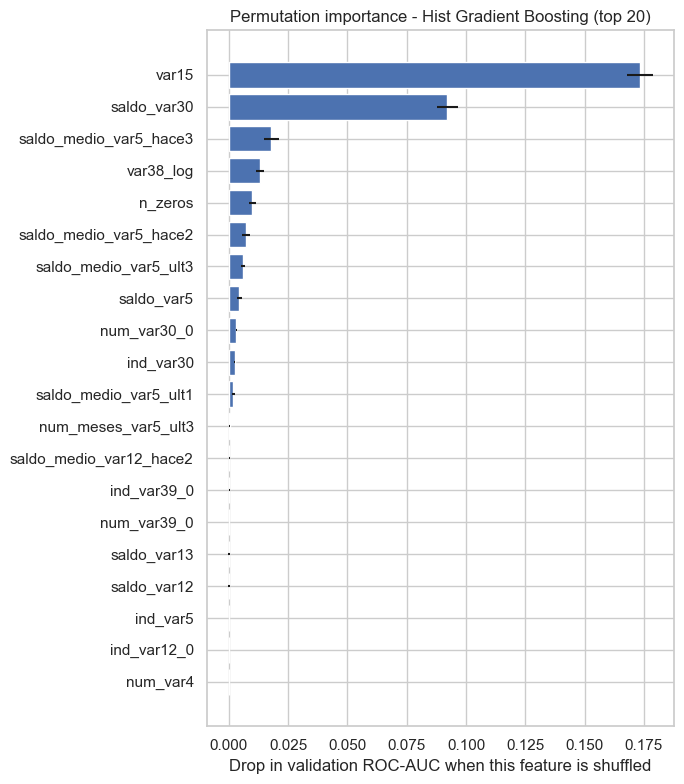

In [52]:
perm_result = permutation_importance(
    final_eval_pipeline, X_val, y_val, scoring="roc_auc",
    n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1
)

perm_importance_df = pd.DataFrame({
    "feature": FINAL_FEATURES,
    "importance_mean": perm_result.importances_mean,
    "importance_std": perm_result.importances_std,
}).sort_values("importance_mean", ascending=False)

top20 = perm_importance_df.head(20)
fig, ax = plt.subplots(figsize=(7, 8))
ax.barh(top20["feature"][::-1], top20["importance_mean"][::-1],
        xerr=top20["importance_std"][::-1], color="#4C72B0")
ax.set_xlabel("Drop in validation ROC-AUC when this feature is shuffled")
ax.set_title(f"Permutation importance - {best_model_algorithm} (top 20)")
plt.tight_layout()
plt.show()

This chart is a good place to sanity-check the engineered features from Section 6: if `n_zeros`
and/or `var38_log` show up here, that is direct evidence (measured on held-out data the model never
trained on) that the feature engineering step earned its place in the model, rather than me just
assuming it would help.

## 15. Refitting on all labeled data, and generating the Kaggle submission

Every metric reported so far (Sections 10-14) came from a model trained **only** on the training
fold and scored on a validation fold it never saw - that is what makes those numbers trustworthy,
and I'm not going to disturb that record.

But now that I've picked a winning algorithm, its hyperparameters, and an imbalance strategy using
that honest process, there's no reason to throw away the ~19,000 customers held out in the
validation fold when it's time to build the model that actually generates Kaggle predictions -
Kaggle's own test set is my real, final unseen data. So I build one more pipeline - same
algorithm, same tuned hyperparameters, same imbalance strategy, decided by everything above - and
refit it on **100% of the labeled data** (`train_part` + `val_part` combined).

> **I keep these two models conceptually separate on purpose:**
> - The **evaluation model** (Sections 9-14) - trained on the training fold only. Its validation
>   scores are my honest, reportable estimate of real-world performance.
> - The **production/submission model** (this section) - trained on all labeled data. It should
>   perform at least as well as the evaluation model in practice (more training data rarely hurts),
>   but I have no held-out set left to score it against - which is exactly why I already did all
>   my reporting with the evaluation model instead.

In [53]:
from sklearn.svm import SVC as _SVCType  # only used for the isinstance guard below

# Recompute var3's imputation value from ALL labeled data now (train_part + val_part) - this is
# the one place in the notebook where using the full labeled set is correct, not leakage: I are
# no longer trying to produce an honest held-out score, I'm preparing the actual model that will
# meet genuinely new customers (the Kaggle test set) for the first time.
var3_mode_full = train_clean.loc[train_clean["var3"] != SENTINEL, "var3"].mode()[0]
train_full_fe = prepare_features(train_clean, var3_mode_full)

X_full = train_full_fe[FINAL_FEATURES]
y_full = train_full_fe["TARGET"]

production_pipeline = clone(calibration_pipelines[FINAL_BALANCING_STRATEGY])

if isinstance(production_pipeline.named_steps["clf"], _SVCType):
    # Same reasoning as Section 9.5: kernel SVM training cost grows too fast with row count to
    # refit on the full ~76,000-row labeled set. I cap the production fit at a larger-but-still-
    # bounded stratified subsample instead of the full data, and say so plainly here.
    SVM_PRODUCTION_SAMPLE_SIZE = 15000
    X_full, _, y_full, _ = train_test_split(
        X_full, y_full, train_size=SVM_PRODUCTION_SAMPLE_SIZE, stratify=y_full,
        random_state=RANDOM_STATE
    )
    print(f"Winner is an SVM - capping the production refit at {SVM_PRODUCTION_SAMPLE_SIZE:,} rows "
          f"for the same cost reasons explained in Section 9.5.")

print(f"Refitting {best_model_algorithm} ({FINAL_BALANCING_STRATEGY}) on {len(X_full):,} labeled rows...")
production_pipeline.fit(X_full, y_full)
print("Done.")

Refitting Hist Gradient Boosting (No rebalancing) on 76,020 labeled rows...


Done.


In [54]:
# Apply the exact same leak-free preparation function to the real Kaggle test set, using the
# var3 mode learned from the full labeled dataset above (never from the test set itself).
test_raw_ids = test_raw["ID"].copy()
test_full_fe = prepare_features(test_raw, var3_mode_full)
X_kaggle_test = test_full_fe[FINAL_FEATURES]

print(f"Prepared Kaggle test features: {X_kaggle_test.shape}")
X_kaggle_test.head()

Prepared Kaggle test features: (75818, 30)


,ind_var30,num_var30,num_meses_var5_ult3,var15,ind_var5,num_var42,saldo_var30,num_var4,n_zeros,var36,var38_log,saldo_medio_var5_ult3,num_var30_0,saldo_medio_var5_hace2,saldo_medio_var5_ult1,saldo_var5,saldo_var13,saldo_medio_var5_hace3,ind_var13_0,var38,saldo_var12,ind_var12_0,num_var5_0,num_var12_0,ind_var5_0,ind_var12,ind_var39_0,num_var39_0,saldo_medio_var13_corto_hace2,saldo_medio_var12_hace2
0,1,3,3,32,1,3,6.0,1,338,3,10.609874,4.80,3,6.0,6.00,6.0,0.0,2.43,0,40532.10,0.0,0,3,0,1,0,1,3,0.0,0.0
1,1,3,3,35,1,3,3.0,1,341,3,10.725198,2.85,3,3.0,3.00,3.0,0.0,2.55,0,45486.72,0.0,0,3,0,1,0,0,0,0.0,0.0
2,1,3,3,23,1,3,30.0,2,322,3,10.757795,66.15,3,90.0,51.45,30.0,0.0,57.00,0,46993.95,0.0,0,3,0,1,0,1,3,0.0,0.0
3,0,0,0,24,0,0,0.0,0,355,99,12.143663,0.00,3,0.0,0.00,0.0,0.0,0.00,0,187898.61,0.0,0,3,0,1,0,1,3,0.0,0.0
4,1,3,3,23,1,3,30.0,1,340,3,11.207089,21.30,3,30.0,30.00,30.0,0.0,3.87,0,73649.73,0.0,0,3,0,1,0,1,3,0.0,0.0


In [55]:
if hasattr(production_pipeline, "predict_proba"):
    test_scores = production_pipeline.predict_proba(X_kaggle_test)[:, 1]
else:
    # SVM without probability=True has no predict_proba - fall back to its decision function,
    # rescaled to look like the [0, 1] range Kaggle submissions for this competition expect.
    raw_scores = production_pipeline.decision_function(X_kaggle_test)
    test_scores = (raw_scores - raw_scores.min()) / (raw_scores.max() - raw_scores.min())

submission = pd.DataFrame({"ID": test_raw_ids, "TARGET": test_scores})
submission.to_csv(os.path.join(OUTPUT_DIR, "submission.csv"), index=False)

print(f"Saved {len(submission):,} predictions to {os.path.join(OUTPUT_DIR, 'submission.csv')}")
submission.head(10)

Saved 75,818 predictions to output\submission.csv


,ID,TARGET
0,2,0.036177
1,5,0.043056
2,6,0.002693
3,7,0.009279
4,9,0.002584
5,11,0.217590
6,12,0.011770
7,15,0.183771
8,16,0.031113
9,17,0.022555


In [56]:
# Persist both models. The production model is what actually generated the submission; the
# evaluation model is kept because its scores are the ones every metric in this notebook reports.
joblib.dump(
    {
        "production_model": production_pipeline,
        "evaluation_model": final_eval_pipeline,
        "features": FINAL_FEATURES,
        "var3_mode_full": var3_mode_full,
        "algorithm": best_model_algorithm,
        "balancing_strategy": FINAL_BALANCING_STRATEGY,
        "val_roc_auc": float(results_df.iloc[0]["Val_ROC_AUC"]),
    },
    os.path.join(MODEL_DIR, "best_model.pkl"),
)
print(f"Saved production + evaluation models ({best_model_algorithm}, {FINAL_BALANCING_STRATEGY}) "
      f"to {MODEL_DIR}/best_model.pkl")

Saved production + evaluation models (Hist Gradient Boosting, No rebalancing) to models/best_model.pkl


## 16. Wrapping up

Quick recap of how I got here:

I started by auditing the raw data - 76,020 customers, 370 anonymized columns, and only about 4%
of them actually dissatisfied. That imbalance shaped basically every decision after it. I cleaned
out columns that were constant or exact duplicates, and noticed two things worth digging into
further: a placeholder value hiding in `var3`, and a badly skewed `var38`.

Before touching either of those, I split the data into training and validation sets - early,
deliberately, so that every statistic I compute afterward (fill-in values, feature selection,
hyperparameters, calibration) only ever learns from the training side, and my validation numbers
stay honest. Then I fixed both issues, added two features of my own (`var38_log` and `n_zeros`),
and picked a final set of ~30 variables by combining four different statistical tests instead of
trusting just one.

From there I trained and compared six different models, kept track of not just each one's
validation score but how stable that score was across cross-validation folds, and used a bootstrap
test to check whether the top model was really better than the runner-up or just got lucky. I also
went back and tested whether SMOTE - which I'd used for all six models - was actually the right
call, or whether something simpler would give more trustworthy probabilities. It turned out it
wasn't the best choice for the winning model, so I switched, based on the actual numbers rather
than a default assumption.

Finally, I added a Precision-Recall view and a "top-K%" table to translate the model's output into
something an actual retention team could act on, looked at what the model was paying attention to,
and retrained on all the labeled data before generating the Kaggle submission.

**What I'd try next, with more time:**

- Try XGBoost, LightGBM, or CatBoost - they often edge out scikit-learn's gradient boosting a bit
  and handle missing values and categorical features more natively.
- Swap `RandomizedSearchCV`'s random sampling for a proper optimizer like Optuna, to search more
  efficiently within the same compute budget.
- Try stacking or blending the strongest models together, since they probably make different kinds
  of mistakes on different customers.
- Revisit how many features I kept (`N_FEATURES` in Section 7) - I used 30 as a reasonable
  default, but it's worth testing a few other values properly.
- If this model were ever used for real (not just a Kaggle score), I'd recalibrate it properly with
  `CalibratedClassifierCV` and figure out an actual operating threshold using real business costs -
  what does an outreach call cost versus losing a customer - instead of just illustrating a few
  candidate thresholds like I did in Section 13.